# 16 · Spatial data readiness (V3 audit, ไม่มีโมเดล)

ตรวจความพร้อมข้อมูลสำหรับ layer คาดการณ์รายพื้นที่/ช่วงถนนและระดับเฝ้าระวังสี **เป็น audit/feasibility เท่านั้น**: ไม่ fit โมเดล ไม่กำหนด threshold/สี ไม่ดาวน์โหลดข้อมูล ไม่แก้ไฟล์ V2

- เชื่อม event_uid ของ V2 ที่ retained ทุกเหตุการณ์กลับไปยังแถว raw ที่ตรวจ hash แล้ว (data index = source_row − 2, ACC_CODE ตรงกัน)
- ตรวจพิกัด/รหัสสายทาง/KM แบบ **flag เท่านั้น** ไม่สลับ ไม่ขยับ ไม่ลบ ค่า raw เก็บไว้คู่ค่าที่ parse
- ตรวจว่ามี polygon จังหวัด/road geometry ที่ตรวจ hash แล้วหรือไม่ ถ้าไม่มีให้สถานะ `PENDING_NOT_VERIFIED`
- ความเบาบางของข้อมูลใช้กลุ่ม **proxy** (จังหวัด/รหัสสายทาง × วัน/6 ชม./7 วัน) นับเฉพาะกลุ่มที่มีเหตุ เพราะยังไม่มี universe ของถนน → **zero label ยังไม่ได้สร้าง**
- กราฟทั้งหมดเป็น **ข้อมูลย้อนหลังเชิงพรรณนา** ไม่ใช่แผนที่ความเสี่ยง

รันใน VS Code ด้วย kernel `.venv` หรือ `.venv/bin/python backend/scripts/run_spatial_readiness.py --output-dir backend/rerun-spatial-<UTC>`

In [1]:
# PARAMETERS (explicit; the runner sets them through environment variables, VS Code users may edit them here)
import os
from pathlib import Path


def _default_backend(c):
    for cand in (c, c.parent, c / 'backend'):
        if (cand / 'config' / 'spatial_readiness_v3.json').is_file():
            return cand
    return c


BACKEND = Path(os.environ.get('ROADAWARE_BACKEND_ROOT') or _default_backend(Path.cwd())).resolve()
OUTPUT_ROOT = Path(os.environ.get('ROADAWARE_V3_OUTPUT_ROOT') or BACKEND).resolve()
OFFLINE = os.environ.get('ROADAWARE_V3_OFFLINE', '1') != '0'  # this audit never downloads; collection is a later Codex-controlled step
CONFIG_PATH = BACKEND / 'config' / 'spatial_readiness_v3.json'
print('backend:', BACKEND, '| output root:', OUTPUT_ROOT, '| offline:', OFFLINE)

backend: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend | output root: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-spatial-012-003 | offline: True


In [2]:
# FUNCTIONS (1/2): hashing, raw linkage, coordinate and route/KM audit. Pure logic; the tests execute these cells directly.
import hashlib
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd


class SpatialReadinessError(RuntimeError):
    pass


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()


def hash_tree(root, rels):
    # relative path -> sha256 for every file under each rel (file or directory); a missing rel is recorded as None
    root, out = Path(root), {}
    for rel in rels:
        p = root / rel
        if p.is_file():
            out[Path(rel).as_posix()] = sha256_file(p)
        elif p.is_dir():
            for q in sorted(p.rglob('*')):
                if q.is_file():
                    out[(Path(rel) / q.relative_to(p)).as_posix()] = sha256_file(q)
        else:
            out[Path(rel).as_posix()] = None
    return out


def changed_keys(before, after):
    return sorted(k for k in set(before) | set(after) if before.get(k) != after.get(k))


def verify_file(path, expected, label):
    path = Path(path)
    if not path.is_file():
        raise SpatialReadinessError(f'{label}: required input {path} not found; this audit only uses local hash-verified files')
    got = sha256_file(path)
    if not expected or got != expected:
        raise SpatialReadinessError(f'{label}: sha256 {got} does not match the pinned {expected} ({path})')
    return got


def _inside(p, root):
    p, root = Path(p).resolve(), Path(root).resolve()
    return p == root or root in p.parents


def check_output_roots(writes, protected):
    for w in writes:
        for p in protected:
            if _inside(w, p) or _inside(p, w):
                raise SpatialReadinessError(f'output location {w} overlaps protected input {p}')


def norm_text(s):
    # V1/V2 whitespace rule (collapse whitespace runs, strip); blanks stay ''
    return s.fillna('').astype(str).map(lambda v: ' '.join(v.split()))


def resolve_alias(columns, aliases, field):
    present = [c for c in aliases.get(field, []) if c in columns]
    if len(present) > 1:
        raise SpatialReadinessError(f'ambiguous header for {field}: {present}')
    return present[0] if present else None


SPATIAL_FIELDS = ('latitude', 'longitude', 'route_code', 'route_name', 'km', 'province', 'agency', 'road_agency_type')


def link_retained_events(events, lineage, raw_by_file, file_meta, aliases, retained='retained', fields=SPATIAL_FIELDS):
    # Exact 1:1 linkage of every retained V2 event to its raw CSV record (data index = source_row - 2). Any identity, index, coverage or
    # duplicate problem raises: no fuzzy join, no ID-only merge, no guessed row. Raw strings are copied untouched (never repaired).
    need = {'events': (events, ('event_uid', 'event_date', 'time_block', 'province_key')),
            'lineage': (lineage, ('event_uid', 'v2_disposition', 'source_file', 'source_row'))}
    for name, (df, cols) in need.items():
        miss = [c for c in cols if c not in df.columns]
        if miss:
            raise SpatialReadinessError(f'{name}: missing columns {miss}')
    n_dup = int(events['event_uid'].duplicated().sum())
    if n_dup:
        raise SpatialReadinessError(f'events: {n_dup} duplicate event_uid')
    lin = lineage[lineage['v2_disposition'] == retained]
    n_dup = int(lin['event_uid'].duplicated().sum())
    if n_dup:
        raise SpatialReadinessError(f'lineage: {n_dup} duplicate retained event_uid')
    ev_set, lin_set = set(events['event_uid']), set(lin['event_uid'])
    if ev_set != lin_set:
        raise SpatialReadinessError(f'retained lineage UIDs != events UIDs: {len(ev_set - lin_set)} events lack lineage, '
                                    f'{len(lin_set - ev_set)} lineage UIDs lack an event')
    rows = pd.to_numeric(lin['source_row'], errors='coerce')
    bad = rows.isna() | (rows != np.floor(rows))
    if bad.any():
        raise SpatialReadinessError(f'lineage: {int(bad.sum())} retained rows have a non-integer source_row')
    lin = lin.assign(source_row=rows.astype('int64'))
    n_dup = int(lin.duplicated(['source_file', 'source_row']).sum())
    if n_dup:
        raise SpatialReadinessError(f'lineage: {n_dup} retained UIDs point at an already-used raw record')
    unknown = sorted(set(lin['source_file']) - set(raw_by_file))
    if unknown:
        raise SpatialReadinessError(f'lineage references raw files that were not loaded and hash-verified: {unknown}')
    headers, frames = {}, []
    for fname, l in lin.groupby('source_file', sort=True):
        raw, meta = raw_by_file[fname], file_meta[fname]
        n = len(raw)
        oob = (l['source_row'] < 2) | (l['source_row'] > n + 1)
        if oob.any():
            raise SpatialReadinessError(f'{fname}: {int(oob.sum())} source_row values outside [2, {n + 1}]')
        idx = l['source_row'].to_numpy() - 2
        r = raw.iloc[idx]
        idcol = resolve_alias(raw.columns, aliases, 'acc_code')
        if idcol is None:
            raise SpatialReadinessError(f'{fname}: no ACC_CODE column, so no retained V2 event can be linked to it')
        expected = (str(meta['be_year']) + ':' + norm_text(r[idcol])).to_numpy()
        uids = l['event_uid'].to_numpy()
        mism = expected != uids
        if mism.any():
            raise SpatialReadinessError(f'{fname}: {int(mism.sum())} event_uid != BE-year:ACC_CODE at the lineage row '
                                        f'(first: {uids[mism][0]} vs raw {expected[mism][0]})')
        out = pd.DataFrame({'event_uid': uids, 'source_file': fname, 'source_sha256': meta['sha256'],
                            'source_row': l['source_row'].to_numpy(), 'raw_index': idx, 'be_year': int(meta['be_year']),
                            'ce_year': int(meta['ce_year'])})
        for field in fields:
            col = resolve_alias(raw.columns, aliases, field)
            headers.setdefault(field, {})[fname] = col
            out['raw_' + field] = r[col].to_numpy() if col else ''
        frames.append(out)
    linked = pd.concat(frames, ignore_index=True).merge(events[['event_uid', 'event_date', 'time_block', 'province_key']],
                                                        on='event_uid', how='inner', validate='one_to_one')
    if len(linked) != len(events):
        raise SpatialReadinessError(f'linkage produced {len(linked)} rows for {len(events)} events')
    linked['event_year'] = pd.to_numeric(linked['event_date'].str[:4], errors='coerce')
    return linked.sort_values(['source_file', 'source_row'], kind='stable').reset_index(drop=True), headers


def raw_disposition_frame(raw_by_file, file_meta, lineage, aliases, fields=SPATIAL_FIELDS):
    # Every raw record of every verified file with the V2 disposition(s) lineage recorded for it (read-only; never re-decided here).
    lin = lineage.assign(_row=pd.to_numeric(lineage['source_row'], errors='coerce'))
    n_unparsed = int(lin['_row'].isna().sum())
    lin = lin.dropna(subset=['_row'])
    disp = lin.groupby(['source_file', '_row'])['v2_disposition'].agg(lambda v: '|'.join(sorted(set(v))))
    frames = []
    for fname in sorted(raw_by_file):
        raw, meta = raw_by_file[fname], file_meta[fname]
        out = pd.DataFrame({'source_file': fname, 'source_row': np.arange(2, len(raw) + 2), 'be_year': int(meta['be_year']),
                            'ce_year': int(meta['ce_year'])})
        for field in fields:
            col = resolve_alias(raw.columns, aliases, field)
            out['raw_' + field] = raw[col].to_numpy() if col else ''
        frames.append(out)
    allraw = pd.concat(frames, ignore_index=True)
    key = pd.MultiIndex.from_arrays([allraw['source_file'], allraw['source_row'].astype(float)])
    allraw['v2_disposition'] = disp.reindex(key).fillna('absent_from_lineage').to_numpy()
    in_raw = set(zip(allraw['source_file'], allraw['source_row'].astype(float)))
    orphan = sum(1 for k in disp.index if k[0] in raw_by_file and k not in in_raw)
    return allraw, {'lineage_rows_unparsed_source_row': n_unparsed, 'lineage_keys_without_raw_record': int(orphan)}


COORD_STATUSES = ('missing', 'non_numeric', 'non_finite', 'zero_coordinate', 'swap_candidate_unrepaired', 'outside_broad_bbox',
                  'inside_broad_bbox_unverified')


def decimals_of(s):
    # digits after the decimal point of the raw string; -1 when the raw form is exponent notation (precision unreadable)
    s = s.fillna('').astype(str).str.strip()
    frac = s.str.split('.', n=1).str[1].fillna('')
    dec = frac.str.len().where(s.str.contains('.', regex=False), 0)
    return dec.where(~s.str.contains('[eE]', regex=True), -1).astype(int)


def in_bbox(lat, lon, bbox):
    return (lat >= bbox['lat_min']) & (lat <= bbox['lat_max']) & (lon >= bbox['lon_min']) & (lon <= bbox['lon_max'])


def audit_coordinates(df, bbox, round_dp=6, low_precision_max_decimals=3, repeated_min_events=5, lat_col='raw_latitude',
                      lon_col='raw_longitude'):
    # Flags only. Raw strings stay in df and parsed values sit beside them: nothing is swapped, moved, rounded in place or dropped.
    # 'inside_broad_bbox_unverified' only means the pair falls in a coarse national box (not on a road, in a province or in a datum).
    lat_s = df[lat_col].fillna('').astype(str).str.strip()
    lon_s = df[lon_col].fillna('').astype(str).str.strip()
    lat = pd.to_numeric(lat_s.where(lat_s != ''), errors='coerce')
    lon = pd.to_numeric(lon_s.where(lon_s != ''), errors='coerce')
    missing = (lat_s == '') | (lon_s == '')
    non_numeric = ~missing & (lat.isna() | lon.isna())
    numeric = ~missing & ~non_numeric
    finite = numeric & np.isfinite(lat.fillna(0.0)) & np.isfinite(lon.fillna(0.0))
    inside = finite & in_bbox(lat, lon, bbox)
    zero = finite & ((lat.abs() < 1e-9) | (lon.abs() < 1e-9))
    swapped = finite & ~inside & ~zero & in_bbox(lon, lat, bbox)
    status = np.select([missing.to_numpy(), non_numeric.to_numpy(), (numeric & ~finite).to_numpy(), zero.to_numpy(), swapped.to_numpy(),
                        (finite & ~inside).to_numpy()], list(COORD_STATUSES[:-1]), default=COORD_STATUSES[-1])
    lat_dec, lon_dec = decimals_of(lat_s), decimals_of(lon_s)
    key = (lat.round(round_dp).astype(str) + ',' + lon.round(round_dp).astype(str)).where(finite, '')
    n_same = key.map(key[finite].value_counts()).where(finite, 0).fillna(0).astype(int)
    low = inside & (lat_dec.between(0, low_precision_max_decimals) | lon_dec.between(0, low_precision_max_decimals))
    return pd.DataFrame({'lat_value': lat, 'lon_value': lon, 'coord_status': status, 'lat_decimals': lat_dec, 'lon_decimals': lon_dec,
                         'low_precision_flag': low, 'lat_equals_lon_flag': finite & (lat == lon), 'coord_key': key,
                         'n_events_same_coord': n_same, 'repeated_coord_flag': n_same >= repeated_min_events}, index=df.index)


def audit_route_km(df, km_plausible_max, route_col='raw_route_code', km_col='raw_km'):
    # Formats are classified, never repaired. 'km_plus_m' (e.g. 17+200) parses as km + m/1000, an explicit assumption kept in
    # km_parse_rule; comma forms are ambiguous (decimal vs thousands) and stay unparsed. Parsed is NOT validated against any road.
    r = norm_text(df[route_col])
    has_digit = r.str.contains('[0-9]', regex=True)
    has_letter = r.str.contains('[A-Za-zก-๙]', regex=True)
    route_fmt = np.select([(r == '').to_numpy(), r.str.fullmatch('[0-9]+').to_numpy(), (has_digit & has_letter).to_numpy(),
                           has_letter.to_numpy()], ['missing', 'digits_only', 'letters_and_digits', 'letters_only'], default='other_symbols')
    k = norm_text(df[km_col])
    plain = k.str.fullmatch('[0-9]+([.][0-9]+)?')
    plus = k.str.fullmatch('[0-9]+[+][0-9]+([.][0-9]+)?')
    comma = k.str.contains(',', regex=False) & k.str.fullmatch('[0-9,.]+')
    neg = k.str.fullmatch('-[0-9]+([.][0-9]+)?')
    km_fmt = np.select([(k == '').to_numpy(), plain.to_numpy(), plus.to_numpy(), comma.to_numpy(), neg.to_numpy()],
                       ['missing', 'decimal_number', 'km_plus_m', 'comma_ambiguous', 'negative_number'], default='unparsed_text')
    val = pd.Series(np.nan, index=df.index)
    val.loc[plain] = pd.to_numeric(k[plain])
    if plus.any():
        parts = k[plus].str.split('+', n=1, expand=True)
        val.loc[plus] = pd.to_numeric(parts[0]) + pd.to_numeric(parts[1]) / 1000.0
    val.loc[neg] = pd.to_numeric(k[neg])
    implausible = val.notna() & ((val < 0) | (val > km_plausible_max))
    km_status = np.select([(k == '').to_numpy(), val.isna().to_numpy(), implausible.to_numpy()],
                          ['missing', 'parse_failed', 'implausible_value'], default='parsed_unvalidated')
    rule = np.where(km_fmt == 'km_plus_m', 'km + m/1000 (digits after + assumed metres)',
                    np.where(km_fmt == 'decimal_number', 'decimal km (unit taken from header KM / ก.ม.)', ''))
    return pd.DataFrame({'route_key': r, 'route_format': route_fmt, 'route_leading_zero_flag': r.str.fullmatch('0[0-9]+').to_numpy(),
                         'km_format': km_fmt, 'km_value': val, 'km_status': km_status, 'km_parse_rule': rule}, index=df.index)


def repeated_coordinate_summary(df, top_n):
    # Repeated points are described, never presumed duplicates: a default/landmark/rounded location and a real hotspot look the same.
    rep = df[df['repeated_coord_flag']]
    cols = ['coord_key', 'n_events', 'n_distinct_dates', 'n_distinct_route_keys', 'n_distinct_provinces', 'first_year', 'last_year']
    if rep.empty:
        return pd.DataFrame(columns=cols + ['interpretation']), {'coord_keys_repeated': 0, 'events_at_repeated_keys': 0}
    g = (rep.groupby('coord_key').agg(n_events=('coord_key', 'size'), n_distinct_dates=('event_date', 'nunique'),
                                      n_distinct_route_keys=('route_key', 'nunique'), n_distinct_provinces=('province_key', 'nunique'),
                                      first_year=('ce_year', 'min'), last_year=('ce_year', 'max'))
         .sort_values('n_events', ascending=False, kind='stable').reset_index())
    g['interpretation'] = 'repeated coordinate: default/landmark/rounded point or genuine hotspot; NOT presumed duplicate'
    summary = {'coord_keys_repeated': int(len(g)), 'events_at_repeated_keys': int(g['n_events'].sum()),
               'keys_spanning_multiple_route_keys': int((g['n_distinct_route_keys'] > 1).sum()),
               'keys_spanning_multiple_provinces': int((g['n_distinct_provinces'] > 1).sum()),
               'keys_with_events_on_one_date_only': int((g['n_distinct_dates'] == 1).sum())}
    return g.head(top_n), summary


EARTH_R_M = 6371008.8


def haversine_m(lat1, lon1, lat2, lon2):
    # great-circle distance on a sphere (approximation documented in the report); never metres from raw degree differences
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin((np.radians(lon2) - np.radians(lon1)) / 2) ** 2
    return 2 * EARTH_R_M * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def nearest_neighbour_m(lat, lon, max_points, seed=0):
    # NN great-circle distance via unit-sphere chords (chord -> arc). Above max_points a fixed-seed subsample is used and flagged
    # (subsampling inflates NN distances); memory stays O(max_points).
    from scipy.spatial import cKDTree
    lat, lon = np.asarray(lat, float), np.asarray(lon, float)
    if len(lat) < 2:
        return np.array([]), False
    sub = len(lat) > max_points
    if sub:
        pick = np.random.default_rng(seed).choice(len(lat), max_points, replace=False)
        lat, lon = lat[pick], lon[pick]
    phi, lam = np.radians(lat), np.radians(lon)
    xyz = np.column_stack([np.cos(phi) * np.cos(lam), np.cos(phi) * np.sin(lam), np.sin(phi)])
    d, _ = cKDTree(xyz).query(xyz, k=2)
    return 2 * EARTH_R_M * np.arcsin(np.clip(d[:, 1] / 2, 0, 1)), sub


def q(a, p):
    a = np.asarray(a, float)
    return float(np.quantile(a, p)) if a.size else None


def dispersion_by_group(df, by, max_points, seed=0):
    # Descriptive spread of recorded event points per group: distance to the group's median event point and NN distance.
    # The median event point is NOT a polygon centroid and no geometry is implied.
    rows = []
    for k, g in df.groupby(by, sort=True):
        k = k if isinstance(k, tuple) else (k,)
        lat, lon = g['lat_value'].to_numpy(float), g['lon_value'].to_numpy(float)
        d_km = haversine_m(lat, lon, np.median(lat), np.median(lon)) / 1000.0
        nn, sub = nearest_neighbour_m(lat, lon, max_points, seed)
        row = dict(zip(by, k))
        row.update(n_events_valid_coord=int(len(g)), n_distinct_coord_keys=int(g['coord_key'].nunique()),
                   dist_to_event_median_km_p50=q(d_km, 0.5), dist_to_event_median_km_p90=q(d_km, 0.9),
                   dist_to_event_median_km_max=q(d_km, 1.0), nn_m_p10=q(nn, 0.1), nn_m_p50=q(nn, 0.5), nn_m_p90=q(nn, 0.9),
                   share_nn_same_point=float((nn == 0).mean()) if len(nn) else None, nn_subsampled=bool(sub))
        rows.append(row)
    return pd.DataFrame(rows)

In [3]:
# FUNCTIONS (2/2): geometry/catalog inventory, capability status, proxy support, universe labels, readiness matrix, report helpers.
CAPABILITIES = {'point_in_province': 'province_polygons', 'road_snapping': 'road_network', 'road_universe_denominator': 'road_network',
                'stable_segment_ids': 'road_network', 'route_corridor_intersection': 'road_network'}
REGISTRY_COLS = ['source_id', 'role', 'path', 'pinned_sha256', 'found_sha256', 'status', 'source_url', 'license', 'version', 'format']


def registered_geometry_status(backend, sources):
    rows = []
    for s in sources:
        p = Path(backend) / s['path'] if s.get('path') else None
        got = None
        if p is None or not p.is_file():
            st = 'not_collected'
        else:
            got = sha256_file(p)
            if not s.get('sha256'):
                st = 'present_unpinned_not_usable'
            elif got != s['sha256']:
                st = 'hash_mismatch_not_usable'
            else:
                st = 'hash_verified_content_not_audited'
        rows.append({'source_id': s['id'], 'role': s['role'], 'path': s.get('path') or '', 'pinned_sha256': s.get('sha256') or '',
                     'found_sha256': got or '', 'status': st, 'source_url': s.get('source_url', ''), 'license': s.get('license', ''),
                     'version': s.get('version', ''), 'format': s.get('format', '')})
    return pd.DataFrame(rows, columns=REGISTRY_COLS)


def scan_geometry_files(backend, roots, extensions):
    backend, rows = Path(backend).resolve(), []
    for rel in roots:
        base = backend / rel
        if not base.is_dir():
            rows.append({'search_root': rel, 'path': '', 'bytes': None, 'sha256': '', 'note': 'search root absent'})
            continue
        hits = [p for p in sorted(base.rglob('*')) if p.is_file() and p.name.lower().endswith(tuple(extensions))]
        if not hits:
            rows.append({'search_root': rel, 'path': '', 'bytes': None, 'sha256': '', 'note': 'no geometry-format file found'})
        for p in hits:
            rows.append({'search_root': rel, 'path': p.resolve().relative_to(backend).as_posix(), 'bytes': p.stat().st_size,
                         'sha256': sha256_file(p), 'note': 'found but unregistered: not usable until pinned in config and content-audited'})
    return pd.DataFrame(rows, columns=['search_root', 'path', 'bytes', 'sha256', 'note'])


def capability_status(registry, shapely_available):
    # No branch returns VERIFIED: content, CRS, vintage and coverage audits of geometry are a later task, so this audit can at best
    # report PENDING_CONTENT_AUDIT for a hash-verified dataset.
    rows = []
    for cap, role in CAPABILITIES.items():
        r = registry[(registry['role'] == role) & (registry['status'] == 'hash_verified_content_not_audited')]
        if len(r) == 0:
            st, why = 'PENDING_NOT_VERIFIED', f'no hash-verified {role} dataset in the local registry'
        elif not shapely_available:
            st, why = 'PENDING_NOT_VERIFIED', f'{role} present but shapely is unavailable'
        else:
            st, why = 'PENDING_CONTENT_AUDIT', f'{role} hash-verified; CRS/vintage/coverage/ID audit is a later task'
        rows.append({'capability': cap, 'requires_role': role, 'status': st, 'reason': why})
    return pd.DataFrame(rows)


VECTOR_FORMATS = {'SHP', 'SHAPEFILE', 'ZIPPED SHAPEFILE', 'GEOJSON', 'TOPOJSON', 'GPKG', 'GEOPACKAGE', 'KML', 'KMZ', 'FGB', 'GML', 'WFS',
                  'PBF', 'OSM', 'OSM.PBF'}
IMAGE_SERVICE_FORMATS = {'WMS', 'WMTS', 'TMS', 'XYZ', 'PNG', 'JPG', 'JPEG', 'TIF', 'TIFF', 'PDF'}
TABULAR_FORMATS = {'CSV', 'XLS', 'XLSX', 'JSON', 'API', 'ODS', 'TXT'}


def classify_format(fmt):
    f = ' '.join(str(fmt or '').upper().split())
    if f in VECTOR_FORMATS:
        return 'vector_geometry_candidate'
    if f in IMAGE_SERVICE_FORMATS:
        return 'image_or_map_service_not_vector'
    if f in TABULAR_FORMATS:
        return 'tabular_no_verified_geometry'
    return 'unknown_format'


def catalog_resources(pkg, snapshot, snapshot_sha):
    res = pkg.get('result', pkg) if isinstance(pkg, dict) else {}
    res = res if isinstance(res, dict) else {}
    out = []
    for r in res.get('resources', []) or []:
        out.append({'snapshot': snapshot, 'snapshot_sha256': snapshot_sha, 'package': res.get('name', ''),
                    'license_title': res.get('license_title', '') or res.get('license_id', ''), 'resource_name': r.get('name', ''),
                    'format': r.get('format', ''), 'format_class': classify_format(r.get('format')), 'url': r.get('url', ''),
                    'last_modified': r.get('last_modified') or r.get('created') or '', 'acceptance': 'candidate_metadata_only'})
    return out


def time_keys(df, unit):
    d = pd.to_datetime(df['event_date'], format='%Y-%m-%d', errors='coerce')
    if d.isna().any():
        raise SpatialReadinessError(f'{int(d.isna().sum())} event_date values are not ISO dates')
    day = d.dt.strftime('%Y-%m-%d')
    if unit == 'day':
        return day
    if unit == '6h':
        tb = norm_text(df['time_block'])
        return day + '|' + tb.where(tb != '', 'unknown_block')
    if unit == '7d':
        return (d - pd.to_timedelta(d.dt.weekday, unit='D')).dt.strftime('%Y-%m-%d')
    raise SpatialReadinessError(f'unknown time unit {unit}')


ZERO_NOT_ESTABLISHED = 'NOT_ESTABLISHED: no verified road universe or reporting coverage'


def occupied_support(df, space_col, unit, label):
    # Event-only support over OCCUPIED (space, time) groups. Without a known universe the zero cells are not established, so no zero
    # share, no mean per cell and no label table is produced here.
    t = time_keys(df, unit)
    s = norm_text(df[space_col])
    ok = s != ''
    if unit == '6h':
        ok = ok & ~t.str.endswith('|unknown_block')
    g = pd.DataFrame({'s': s[ok], 't': t[ok]}).groupby(['s', 't']).size()
    return {'grouping': label, 'space_key': space_col, 'time_unit': unit, 'location_level': 'PROXY (not a road segment)',
            'n_events': int(len(df)), 'n_events_without_space_or_time_key': int((~ok).sum()), 'n_space_keys_observed': int(s[ok].nunique()),
            'n_occupied_groups': int(len(g)), 'share_occupied_groups_exactly_1_event': float((g == 1).mean()) if len(g) else None,
            'events_per_occupied_group_p50': q(g, 0.5), 'events_per_occupied_group_p90': q(g, 0.9),
            'events_per_occupied_group_max': float(g.max()) if len(g) else None, 'zero_label_status': ZERO_NOT_ESTABLISHED, 'zero_share': None}


def guard_crossproduct(n_space, n_time, max_cells, label):
    cells = int(n_space) * int(n_time)
    if cells > max_cells:
        raise SpatialReadinessError(f'{label}: {n_space} x {n_time} = {cells} cells exceeds the budget {max_cells}; restrict the study area')
    return cells


OBS_STATUSES = ('observed', 'unknown_reporting', 'outside_network')


def labels_on_universe(event_keys, universe, max_cells):
    # universe: [space_key, time_key, observation_status]. Absence of events becomes an observed zero ONLY where the status is
    # 'observed'; unknown_reporting stays NaN (events there are a lower bound, not a label) and outside_network is never labelled.
    if len(universe) > max_cells:
        raise SpatialReadinessError(f'universe of {len(universe)} cells exceeds the budget {max_cells}')
    bad = sorted(set(universe['observation_status']) - set(OBS_STATUSES))
    if bad:
        raise SpatialReadinessError(f'unknown observation_status values {bad}')
    if universe.duplicated(['space_key', 'time_key']).any():
        raise SpatialReadinessError('universe has duplicate (space_key, time_key) cells')
    counts = event_keys.groupby(['space_key', 'time_key']).size().rename('n_events').reset_index()
    u = universe.merge(counts, on=['space_key', 'time_key'], how='left')
    n_ev = u['n_events'].fillna(0)
    st = u['observation_status']
    u['y_recorded_count'] = np.where(st == 'observed', n_ev, np.nan)
    u['label_status'] = np.select([st == 'observed', (st == 'unknown_reporting') & (n_ev > 0), st == 'unknown_reporting'],
                                  ['observed', 'unknown_reporting_events_lower_bound', 'unknown_reporting_not_zero'],
                                  default='outside_network_not_labelled')
    outside = counts.merge(universe[['space_key', 'time_key']], on=['space_key', 'time_key'], how='left', indicator=True)
    info = {'cells': int(len(u)), 'observed_zero_cells': int(((st == 'observed') & (n_ev == 0)).sum()),
            'unknown_cells': int((st == 'unknown_reporting').sum()),
            'events_in_unknown_cells': int(n_ev[st == 'unknown_reporting'].sum()),
            'events_outside_universe': int(outside.loc[outside['_merge'] == 'left_only', 'n_events'].sum())}
    return u.drop(columns='n_events'), info


FEATURE_STATUSES = ('allow', 'allow_context_only', 'pending', 'blocked')


def feature_readiness(rows, capabilities, reporting_latency_verified=False):
    caps = dict(zip(capabilities['capability'], capabilities['status']))
    out = []
    for r in rows:
        r = dict(r)
        name, st = r['feature_group'], r['status']
        if st not in FEATURE_STATUSES:
            raise SpatialReadinessError(f'{name}: status {st} not in {FEATURE_STATUSES}')
        if r.get('target_day_outcome') and st != 'blocked':
            raise SpatialReadinessError(f'{name}: target-window outcomes are explanatory only and must stay blocked as predictors')
        if r.get('historical_lag') and st != 'blocked' and not reporting_latency_verified:
            raise SpatialReadinessError(f'{name}: historical lags stay blocked until reporting latency is supported')
        req = r.get('requires_capability')
        if req:
            cs = caps.get(req, 'PENDING_NOT_VERIFIED')
            r['capability_status'] = cs
            if cs != 'VERIFIED' and st in ('allow', 'allow_context_only'):
                r['status'] = 'pending'
                r['reason'] = f'{req} is {cs}; ' + r.get('reason', '')
        out.append(r)
    return pd.DataFrame(out)


ROW_LEVEL_COLUMNS = ('event_uid', 'source_row', 'raw_index', 'acc_code')


def assert_aggregate(df, name):
    bad = [c for c in df.columns if c in ROW_LEVEL_COLUMNS]
    if bad:
        raise SpatialReadinessError(f'{name}: row-level columns {bad} may not be written to the tracked report directory')


def split_of_year(y, years):
    for k, v in years.items():
        if int(y) in v:
            return k
    return 'outside_configured_years'


def to_jsonable(v):
    if isinstance(v, dict):
        return {str(k): to_jsonable(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [to_jsonable(x) for x in v]
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (float, np.floating)):
        return float(v) if math.isfinite(v) else None
    return v


def fmt_cell(v):
    if v is None or (isinstance(v, float) and not math.isfinite(v)):
        return ''
    if isinstance(v, (float, np.floating)):
        return f'{v:,.3f}'.rstrip('0').rstrip('.')
    if isinstance(v, (int, np.integer)) and not isinstance(v, bool):
        return f'{v:,}'
    return str(v).replace('|', '/')


def md_table(df, max_rows=40):
    d = df.head(max_rows)
    lines = ['| ' + ' | '.join(str(c) for c in d.columns) + ' |', '|' + '---|' * len(d.columns)]
    lines += ['| ' + ' | '.join(fmt_cell(v) for v in row) + ' |' for row in d.itertuples(index=False)]
    if len(df) > max_rows:
        lines.append(f'(แสดง {max_rows} จาก {len(df)} แถว; ฉบับเต็มอยู่ใน CSV)')
    return chr(10).join(lines)

In [4]:
# Setup: config, output roots (never overwriting an earlier run), read-only hash manifest of protected inputs BEFORE the audit
import datetime as dt
import importlib.util
import platform
import sys

import matplotlib
import matplotlib.font_manager
import matplotlib.pyplot as plt
from IPython.display import display

if not CONFIG_PATH.is_file():
    raise SpatialReadinessError(f'config {CONFIG_PATH} not found: set ROADAWARE_BACKEND_ROOT to the backend directory')
CFG = json.loads(CONFIG_PATH.read_text('utf-8'))
VERSION = CFG['version']
REPORT_DIR = OUTPUT_ROOT / CFG['outputs']['report_dir']
DATA_DIR = OUTPUT_ROOT / CFG['outputs']['data_dir']
MANIFEST_PATH = REPORT_DIR / 'spatial_readiness_manifest.json'
if not OFFLINE:
    raise SpatialReadinessError('ROADAWARE_V3_OFFLINE=0 was requested, but this audit has no online step; collection is a later Codex task')
if MANIFEST_PATH.exists() or (REPORT_DIR.is_dir() and any(REPORT_DIR.iterdir())):
    raise SpatialReadinessError(f'{REPORT_DIR} already holds an earlier run; use a NEW output root (e.g. backend/rerun-spatial-<UTC stamp>)')
PROTECTED_ABS = [(BACKEND / p).resolve() for p in CFG['protected_paths']]
check_output_roots([REPORT_DIR.resolve(), DATA_DIR.resolve()], PROTECTED_ABS)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)
STARTED_UTC = dt.datetime.now(dt.timezone.utc).isoformat()
HASH_BEFORE = hash_tree(BACKEND, CFG['protected_paths'])
CHECKS, OUTPUTS, DATA_OUTPUTS = [], [], []


def check(name, passed, value=None, note='', fatal=True):
    CHECKS.append({'check': name, 'status': 'pass' if passed else ('FAIL' if fatal else 'mismatch'), 'value': to_jsonable(value), 'note': note})
    if fatal and not passed:
        raise SpatialReadinessError(f'check failed: {name} (value={value}) {note}')


def save_csv(df, name):
    assert_aggregate(df, name)
    p = REPORT_DIR / name
    df.to_csv(p, index=False, encoding='utf-8')
    OUTPUTS.append({'path': name, 'rows': int(len(df)), 'sha256': sha256_file(p)})
    return p


def save_fig(fig, name):
    p = REPORT_DIR / name
    fig.savefig(p, dpi=120, bbox_inches='tight')
    OUTPUTS.append({'path': name, 'rows': None, 'sha256': sha256_file(p)})
    plt.show()


absent = [k for k, v in HASH_BEFORE.items() if v is None]
print(f'{VERSION}: protected files hashed before the run = {len(HASH_BEFORE) - len(absent)}; absent protected paths = {absent}')

spatial_readiness_v3.0: protected files hashed before the run = 345; absent protected paths = []


## 1. ตรวจ hash ของ input และ metadata ของแหล่งข้อมูล
ไฟล์ V2 ต้องตรงกับ hash ที่ notebook 10 บันทึก และไฟล์ raw ต้องตรงทั้ง config และ source_manifest ถ้าไม่ตรงหรือไม่มีไฟล์ notebook จะหยุดพร้อมเหตุผล ไม่สร้างข้อมูลแทน

In [5]:
INP = CFG['inputs']
INPUT_HASHES = {}
for key in ('events_v2', 'row_lineage_v2', 'panel_daily_v2', 'data_pipeline_config'):
    INPUT_HASHES[INP[key]['path']] = verify_file(BACKEND / INP[key]['path'], INP[key]['sha256'], key)
for key in ('raw_manifest', 'preparation_manifest'):
    p = BACKEND / INP[key]
    if not p.is_file():
        raise SpatialReadinessError(f'{key}: {p} not found')
    INPUT_HASHES[INP[key]] = sha256_file(p)
PREP = json.loads((BACKEND / INP['preparation_manifest']).read_text('utf-8'))
prep_out = {d.get('path'): d.get('sha256') for d in PREP.get('data_outputs', [])}
for key in ('events_v2', 'row_lineage_v2', 'panel_daily_v2'):
    name = Path(INP[key]['path']).name
    check(f'{key} equals the accepted notebook 10 data output', prep_out.get(name) == INP[key]['sha256'], prep_out.get(name))
pin = [x.get('sha256') for x in PREP.get('inputs', []) if x.get('role') == 'v1_raw_manifest']
check('raw source_manifest equals the copy notebook 10 recorded', bool(pin) and pin[0] == INPUT_HASHES[INP['raw_manifest']], pin[:1])
RAW_MANIFEST = json.loads((BACKEND / INP['raw_manifest']).read_text('utf-8'))
ALIASES = json.loads((BACKEND / INP['data_pipeline_config']['path']).read_text('utf-8'))['schema_aliases']
YEARS = CFG['years']
LINK_YEARS = set(YEARS['train']) | set(YEARS['seen_diagnostic'])
DIAG_YEARS = set(YEARS['diagnostic_no_id'])
RAW_BY_FILE, FILE_META, RAW_DIAG, DIAG_META, META_ROWS = {}, {}, {}, {}, []
manifest_text = json.dumps(RAW_MANIFEST, ensure_ascii=False).lower()
DATUM_KEYS_FOUND = [k for k in CFG['datum_metadata_keys'] if k in manifest_text]
for e in RAW_MANIFEST['files']:
    year, fname = int(e['ce_year']), e['file']
    if year not in LINK_YEARS | DIAG_YEARS:
        continue
    pinned = INP['raw_files'].get(fname)
    check(f'{fname}: source_manifest hash equals config pin', e['sha256'] == pinned, e['sha256'])
    INPUT_HASHES[e['path']] = verify_file(BACKEND / e['path'], pinned, fname)
    raw = pd.read_csv(BACKEND / e['path'], dtype=str, keep_default_na=False, encoding=e['encoding'])
    check(f'{fname}: record count equals source_manifest', len(raw) == int(e['rows']), len(raw))
    meta = {'be_year': int(e['be_year']), 'ce_year': year, 'sha256': pinned}
    (RAW_DIAG if year in DIAG_YEARS else RAW_BY_FILE)[fname] = raw
    (DIAG_META if year in DIAG_YEARS else FILE_META)[fname] = meta
    hdr = {f: resolve_alias(raw.columns, ALIASES, f) for f in SPATIAL_FIELDS + ('acc_code',)}
    META_ROWS.append({'source_file': fname, 'ce_year': year, 'role': 'diagnostic_no_id (audited, never linked)' if year in DIAG_YEARS else 'linked',
                      'encoding': e['encoding'], 'records': len(raw), 'read_as': 'str; parsed values kept beside raw strings',
                      **{'header_' + f: (h or 'ABSENT') for f, h in hdr.items()},
                      'crs_or_datum_documented': ('yes: ' + ','.join(DATUM_KEYS_FOUND)) if DATUM_KEYS_FOUND else 'NOT DOCUMENTED (datum unknown)'})
missing_years = sorted((LINK_YEARS | DIAG_YEARS) - {m['ce_year'] for m in list(FILE_META.values()) + list(DIAG_META.values())})
check('every configured year has a verified raw file', not missing_years, missing_years)
SOURCE_META = pd.DataFrame(META_ROWS)
save_csv(SOURCE_META, 'source_metadata_audit.csv')
display(SOURCE_META)

,source_file,ce_year,role,encoding,records,read_as,header_latitude,header_longitude,header_route_code,header_route_name,header_km,header_province,header_agency,header_road_agency_type,header_acc_code,crs_or_datum_documented
0,accidents_2564_original.csv,2021,linked,utf-8-sig,20062,str; parsed values kept beside raw strings,LATITUDE,LONGITUDE,รหัสสายทาง,สายทาง,KM,จังหวัด,หน่วยงาน,สายทางหน่วยงาน,ACC_CODE,NOT DOCUMENTED (datum unknown)
1,accidents_2565_original.csv,2022,linked,utf-8-sig,20566,str; parsed values kept beside raw strings,LATITUDE,LONGITUDE,รหัสสายทาง,สายทาง,KM,จังหวัด,หน่วยงาน,สายทางหน่วยงาน,ACC_CODE,NOT DOCUMENTED (datum unknown)
2,accidents_2566_original.csv,2023,linked,utf-8-sig,23841,str; parsed values kept beside raw strings,LATITUDE,LONGITUDE,รหัสสายทาง,สายทาง,KM,จังหวัด,หน่วยงาน,สายทางหน่วยงาน,ACC_CODE,NOT DOCUMENTED (datum unknown)
3,accidents_2567_original.csv,2024,linked,utf-8-sig,23952,str; parsed values kept beside raw strings,LATITUDE,LONGITUDE,รหัสสายทาง,สายทาง,KM,จังหวัด,หน่วยงาน,สายทางหน่วยงาน,ACC_CODE,NOT DOCUMENTED (datum unknown)
4,accidents_2568_original.csv,2025,linked,utf-8-sig,23715,str; parsed values kept beside raw strings,LATITUDE,LONGITUDE,รหัสสายทาง,สายทาง,KM,จังหวัด,หน่วยงาน,สายทางหน่วยงาน,ACC_CODE,NOT DOCUMENTED (datum unknown)
5,accidents_2569_original.csv,2026,"diagnostic_no_id (audited, never linked)",utf-8-sig,15239,str; parsed values kept beside raw strings,LATITUDE,LONGITUDE,รหัสสายทาง,สายทาง,ก.ม.,จังหวัด,หน่วยงาน,สายทางหน่วยงาน,ABSENT,NOT DOCUMENTED (datum unknown)


## 2. Raw linkage ของ V2 retained events
ทุก event_uid ต้องมี lineage หนึ่งแถว ชี้ไปยัง raw record เดียวที่ยังไม่ถูกใช้ และ BE-year:ACC_CODE ที่แถวนั้นต้องเท่ากับ UID ห้าม join ด้วย ID อย่างเดียวหรือเดาแถว

In [6]:
EVENTS = pd.read_csv(BACKEND / INP['events_v2']['path'], dtype=str, keep_default_na=False)
LINEAGE = pd.read_csv(BACKEND / INP['row_lineage_v2']['path'], dtype=str, keep_default_na=False)
RETAINED = CFG['retained_disposition']
LINKED, HEADERS = link_retained_events(EVENTS, LINEAGE, RAW_BY_FILE, FILE_META, ALIASES, RETAINED)
check('every retained V2 event linked exactly once', len(LINKED) == CFG['expected_retained_events'] and LINKED['event_uid'].is_unique, len(LINKED))
check('linked UIDs carry the BE year of their source file',
      bool((LINKED['event_uid'].str.split(':').str[0] == LINKED['be_year'].astype(str)).all()))
N_YEAR_MISMATCH = int((LINKED['event_year'] != LINKED['ce_year']).sum())
check('accepted event_date year equals source-file CE year', N_YEAR_MISMATCH == 0, N_YEAR_MISMATCH,
      'reported only: accepted V2 dates are never re-interpreted here', fatal=False)
LINKED['_year_mismatch'] = LINKED['event_year'] != LINKED['ce_year']
LINK_RECON = (LINKED.groupby(['source_file', 'ce_year', 'source_sha256'], as_index=False)
              .agg(n_linked=('event_uid', 'size'), min_source_row=('source_row', 'min'), max_source_row=('source_row', 'max'),
                   n_event_year_ne_file_year=('_year_mismatch', 'sum')))
LINKED = LINKED.drop(columns='_year_mismatch')
LINK_RECON['raw_records'] = LINK_RECON['source_file'].map(lambda f: len(RAW_BY_FILE[f]))
LINK_RECON['split'] = LINK_RECON['ce_year'].map(lambda y: split_of_year(y, YEARS))
LINK_RECON['identity_rule'] = 'event_uid == BE-year:norm(ACC_CODE) at data index source_row-2'
LIN_DISP = LINEAGE['v2_disposition'].value_counts().rename_axis('v2_disposition').rename('lineage_rows').reset_index()
save_csv(LINK_RECON, 'linkage_reconciliation.csv')
save_csv(LIN_DISP, 'lineage_disposition_counts.csv')
display(LINK_RECON)
display(LIN_DISP)

,source_file,ce_year,source_sha256,n_linked,min_source_row,max_source_row,n_event_year_ne_file_year,raw_records,split,identity_rule
0,accidents_2564_original.csv,2021,044f8ae0a918ec25139bef24257fe274fd17d9bfab2512...,19996,2,20063,0,20062,train,event_uid == BE-year:norm(ACC_CODE) at data in...
1,accidents_2565_original.csv,2022,6f7c543a302906925e32fbf6b8da5d2b1920266489ae1c...,20492,2,20567,0,20566,train,event_uid == BE-year:norm(ACC_CODE) at data in...
2,accidents_2566_original.csv,2023,4d6dbfa4b8e1f4dd476d81062a01c10a858b7acd174fef...,20490,4,22924,0,23841,train,event_uid == BE-year:norm(ACC_CODE) at data in...
3,accidents_2567_original.csv,2024,2ca1e832a4fa8d29ef6adfe52623a9b447a7f0b12e61e6...,21788,2,23949,0,23952,seen_diagnostic,event_uid == BE-year:norm(ACC_CODE) at data in...
4,accidents_2568_original.csv,2025,b163fa91170fa7df76b8d71b4eb629ff7ca4ef220bea6c...,23542,2,23716,0,23715,seen_diagnostic,event_uid == BE-year:norm(ACC_CODE) at data in...


,v2_disposition,lineage_rows
0,retained,106308
1,diagnostic,15239
2,quarantined,5828


## 3. Audit พิกัด / รหัสสายทาง / KM (flag เท่านั้น)
ตรวจแยก **retained V2** กับ **raw ทุกแถวตาม disposition เดิมของ V2** (รวมปี 2026 ที่ไม่มี ID เป็น diagnostic) การอยู่ใน bounding box ไม่ได้ยืนยันว่าอยู่บนถนน/ในจังหวัด/datum ถูก, swap candidate ไม่ถูกสลับให้, จุดซ้ำไม่ถือว่าเป็นเหตุซ้ำ

In [7]:
BBOX, CA = CFG['thailand_broad_bbox'], CFG['coordinate_audit']


def run_audits(df):
    return pd.concat([df, audit_coordinates(df, BBOX, CA['round_dp'], CA['low_precision_max_decimals'], CA['repeated_min_events']),
                      audit_route_km(df, CFG['km_plausible_max'])], axis=1)


RET = run_audits(LINKED)
RET['split'] = RET['ce_year'].map(lambda y: split_of_year(y, YEARS))
ALLRAW, LIN_INFO = raw_disposition_frame({**RAW_BY_FILE, **RAW_DIAG}, {**FILE_META, **DIAG_META}, LINEAGE, ALIASES)
ALLRAW = run_audits(ALLRAW)
ALLRAW['split'] = ALLRAW['ce_year'].map(lambda y: split_of_year(y, YEARS))
check('lineage rows with unparseable source_row', LIN_INFO['lineage_rows_unparsed_source_row'] == 0, LIN_INFO, fatal=False)
ret_all = ALLRAW[ALLRAW['v2_disposition'] == RETAINED]
check('raw-wide audit holds exactly the linked retained records', len(ret_all) == len(RET), len(ret_all))
a = ret_all['coord_status'].value_counts().sort_index()
b = RET['coord_status'].value_counts().sort_index()
check('retained coordinate statuses identical in the linked and raw-wide audits', a.equals(b), a.to_dict())
COORD_RET = RET.groupby(['ce_year', 'split', 'coord_status']).size().rename('n_events').reset_index()
COORD_RAW = ALLRAW.groupby(['ce_year', 'split', 'v2_disposition', 'coord_status']).size().rename('n_records').reset_index()
save_csv(COORD_RET, 'coordinate_status_retained_by_year.csv')
save_csv(COORD_RAW, 'coordinate_status_raw_by_disposition_year.csv')
display(COORD_RET.pivot_table(index='coord_status', columns='ce_year', values='n_events', aggfunc='sum', fill_value=0))
display(COORD_RAW.pivot_table(index=['v2_disposition', 'coord_status'], columns='ce_year', values='n_records', aggfunc='sum', fill_value=0))

ce_year,2021,2022,2023,2024,2025
coord_status,,,,,
inside_broad_bbox_unverified,19996,20492,20490,21788,23542


ce_year                                       2021   2022   2023   2024  \
v2_disposition coord_status                                               
diagnostic     inside_broad_bbox_unverified      0      0      0      0   
               missing                           0      0      0      0   
quarantined    inside_broad_bbox_unverified      1      1   3171   1926   
               missing                          65     73    176    238   
               outside_broad_bbox                0      0      4      0   
               swap_candidate_unrepaired         0      0      0      0   
retained       inside_broad_bbox_unverified  19996  20492  20490  21788   

ce_year                                       2025   2026  
v2_disposition coord_status                                
diagnostic     inside_broad_bbox_unverified      0  15088  
               missing                           0    151  
quarantined    inside_broad_bbox_unverified      2      0  
               missing                         169      0  
               outside_broad_bbox                1      0  
               swap_candidate_unrepaired         1      0  
retained       inside_broad_bbox_unverified  23542      0

In [8]:
ROUTE_FMT = RET.groupby(['ce_year', 'route_format']).size().rename('n_events').reset_index()
ROUTE_FMT_LZ = RET.groupby('ce_year')['route_leading_zero_flag'].sum().rename('n_route_codes_with_leading_zero').reset_index()
KM_FMT = RET.groupby(['ce_year', 'km_format', 'km_status', 'km_parse_rule']).size().rename('n_events').reset_index()
KM_DISP = ALLRAW.groupby(['split', 'v2_disposition', 'km_format', 'km_status']).size().rename('n_records').reset_index()
ROUTE_KM = (RET.assign(route_present=RET['route_format'] != 'missing', km_present=RET['km_format'] != 'missing')
            .groupby(['split', 'route_present', 'km_present']).size().rename('n_events').reset_index())
PROV_PAIRS = (RET.assign(raw_province_norm=norm_text(RET['raw_province']))
              .loc[lambda d: d['raw_province_norm'] != d['province_key']]
              .groupby(['province_key', 'raw_province_norm']).size().rename('n_events').reset_index()
              .sort_values('n_events', ascending=False, kind='stable'))
PROV_PAIRS['note'] = 'raw province text differs from V2 province_key (naming alias or disagreement; not adjudicated here)'
for name, df in (('route_format_by_year.csv', ROUTE_FMT.merge(ROUTE_FMT_LZ, on='ce_year')), ('km_format_status_by_year.csv', KM_FMT),
                 ('km_status_raw_by_disposition.csv', KM_DISP), ('route_km_presence_retained.csv', ROUTE_KM),
                 ('province_label_pairs_retained.csv', PROV_PAIRS)):
    save_csv(df, name)
display(ROUTE_FMT.pivot_table(index='route_format', columns='ce_year', values='n_events', aggfunc='sum', fill_value=0))
display(KM_FMT.pivot_table(index=['km_format', 'km_status'], columns='ce_year', values='n_events', aggfunc='sum', fill_value=0))
display(ROUTE_KM)
display(PROV_PAIRS.head(20))

ce_year,2021,2022,2023,2024,2025
route_format,,,,,
digits_only,18655,19243,20490,20606,22370
letters_and_digits,1341,1249,0,1180,1165
missing,0,0,0,2,7


,ce_year,2021,2022,2023,2024,2025
km_format,km_status,,,,,
decimal_number,parsed_unvalidated,19922,20414,20442,21739,23474
missing,missing,74,78,48,49,68


,split,route_present,km_present,n_events
0,seen_diagnostic,False,False,9
1,seen_diagnostic,True,False,108
2,seen_diagnostic,True,True,45213
3,train,True,False,200
4,train,True,True,60778


,province_key,raw_province_norm,n_events,note


In [9]:
INSIDE = RET['coord_status'] == 'inside_broad_bbox_unverified'
REPEATED_TOP, REPEATED_SUMMARY = repeated_coordinate_summary(RET[INSIDE], CA['repeated_top_n'])
med = RET[INSIDE].groupby('province_key')[['lat_value', 'lon_value']].median().reindex(RET['province_key'])
RET['dist_to_province_event_median_km'] = np.where(INSIDE, haversine_m(RET['lat_value'].to_numpy(float), RET['lon_value'].to_numpy(float),
                                                                       med['lat_value'].to_numpy(float), med['lon_value'].to_numpy(float)) / 1000.0, np.nan)
FAR_KM = CA['far_from_province_median_km']
RET['far_from_province_event_median_flag'] = RET['dist_to_province_event_median_km'] > FAR_KM
FLAGS = (RET.assign(_inside=INSIDE)
         .groupby('split').agg(n_events=('event_uid', 'size'), n_inside_bbox_unverified=('_inside', 'sum'),
                               n_low_precision=('low_precision_flag', 'sum'), n_lat_equals_lon=('lat_equals_lon_flag', 'sum'),
                               n_at_repeated_coordinate=('repeated_coord_flag', 'sum'),
                               n_far_from_province_event_median=('far_from_province_event_median_flag', 'sum')).reset_index())
FLAGS['far_rule'] = (f'great-circle distance > {FAR_KM} km from the median recorded point of its own province '
                     '(candidate inconsistency, not point-in-province)')
save_csv(REPEATED_TOP, 'repeated_coordinates_top.csv')
save_csv(FLAGS, 'coordinate_flags_by_split.csv')
print('repeated-coordinate summary:', REPEATED_SUMMARY)
display(FLAGS)
display(REPEATED_TOP.head(15))

repeated-coordinate summary: {'coord_keys_repeated': 188, 'events_at_repeated_keys': 1278, 'keys_spanning_multiple_route_keys': 2, 'keys_spanning_multiple_provinces': 0, 'keys_with_events_on_one_date_only': 0}


,split,n_events,n_inside_bbox_unverified,n_low_precision,n_lat_equals_lon,n_at_repeated_coordinate,n_far_from_province_event_median,far_rule
0,seen_diagnostic,45330,45330,22,0,545,25,great-circle distance > 150 km from the median...
1,train,60978,60978,14,0,733,23,great-circle distance > 150 km from the median...


,coord_key,n_events,n_distinct_dates,n_distinct_route_keys,n_distinct_provinces,first_year,last_year,interpretation
0,"13.665957,100.850176",29,29,1,1,2021,2022,repeated coordinate: default/landmark/rounded ...
1,"13.648448,100.418724",15,15,1,1,2023,2025,repeated coordinate: default/landmark/rounded ...
2,"12.946795,100.928387",14,14,1,1,2023,2025,repeated coordinate: default/landmark/rounded ...
3,"13.661887,100.438474",14,14,1,1,2023,2025,repeated coordinate: default/landmark/rounded ...
4,"13.729518,100.743578",14,14,1,1,2021,2022,repeated coordinate: default/landmark/rounded ...
5,"13.730623,100.720915",14,14,1,1,2022,2023,repeated coordinate: default/landmark/rounded ...
6,"13.578051,100.883734",13,12,1,1,2024,2025,repeated coordinate: default/landmark/rounded ...
7,"13.665956,100.850177",13,13,1,1,2022,2023,repeated coordinate: default/landmark/rounded ...
8,"13.66842,100.846352",13,13,1,1,2021,2022,repeated coordinate: default/landmark/rounded ...
9,"13.587537,100.839123",12,11,1,1,2024,2025,repeated coordinate: default/landmark/rounded ...


## 4. Geometry ที่มีอยู่จริง: polygon จังหวัด / road network
ค้นเฉพาะไฟล์ในเครื่อง (ไม่ดาวน์โหลด) แหล่งในแผนงานเป็น **candidate metadata** ไม่ใช่ geometry ที่รับรอง หากไม่มี dataset ที่ pin hash ไว้ ความสามารถทุกอย่างคง `PENDING_NOT_VERIFIED`

In [10]:
OPTIONAL_LIBS = {m: importlib.util.find_spec(m) is not None for m in ('shapely', 'scipy', 'pyproj', 'h3', 'geopandas', 'pyogrio', 'fiona')}
GEO_REGISTRY = registered_geometry_status(BACKEND, CFG['geometry_sources'])
GEO_SCAN = scan_geometry_files(BACKEND, CFG['geometry_search_roots'], CFG['geometry_extensions'])
CAPS = capability_status(GEO_REGISTRY, OPTIONAL_LIBS['shapely'])
check('no geometry capability is reported as verified by this audit', not CAPS['status'].eq('VERIFIED').any(), CAPS['status'].tolist())
CATALOG_ROWS = []
for rel in CFG['catalog_snapshots']:
    p = BACKEND / rel
    if not p.is_file():
        CATALOG_ROWS.append({'snapshot': rel, 'acceptance': 'snapshot absent'})
        continue
    h = sha256_file(p)
    INPUT_HASHES[rel] = h
    try:
        pkg = json.loads(p.read_text('utf-8'))
    except ValueError as exc:
        CATALOG_ROWS.append({'snapshot': rel, 'snapshot_sha256': h, 'acceptance': f'unreadable JSON: {exc}'})
        continue
    CATALOG_ROWS += catalog_resources(pkg, rel, h) or [{'snapshot': rel, 'snapshot_sha256': h, 'acceptance': 'no CKAN resources list'}]
for c in CFG['geometry_sources']:
    CATALOG_ROWS.append({'snapshot': 'config candidate (planning link)', 'package': c['id'], 'license_title': c.get('license', ''),
                         'resource_name': c.get('description', ''), 'format': c.get('format', ''), 'format_class': classify_format(c.get('format')),
                         'url': c.get('source_url', ''), 'last_modified': c.get('version', ''), 'acceptance': 'candidate_metadata_only_not_downloaded'})
CATALOG = pd.DataFrame(CATALOG_ROWS)
LIBS = pd.DataFrame([{'module': k, 'importable_in_kernel': v} for k, v in OPTIONAL_LIBS.items()])
for name, df in (('geometry_registry.csv', GEO_REGISTRY), ('geometry_file_scan.csv', GEO_SCAN), ('capability_status.csv', CAPS),
                 ('catalog_resources.csv', CATALOG), ('optional_libraries.csv', LIBS)):
    save_csv(df, name)
display(GEO_REGISTRY[['source_id', 'role', 'format', 'status', 'license', 'source_url']])
display(GEO_SCAN)
display(CAPS)
display(CATALOG.groupby(['snapshot', 'format_class'], dropna=False).size().rename('n_resources').reset_index())
display(LIBS)

,source_id,role,format,status,license,source_url
0,mot_transportgis_road_network,road_network,WMS,not_collected,to verify at collection,https://datagov.mot.go.th/th/dataset/transportgis
1,osm_thailand_snapshot,road_network,PBF,not_collected,ODbL 1.0 (attribution required),https://www.openstreetmap.org/copyright
2,geoboundaries_tha_adm1,province_polygons,GEOJSON,not_collected,gbOpen (verify at collection),https://github.com/wmgeolab/geoBoundaries/raw/...


,search_root,path,bytes,sha256,note
0,data/external_v2,data/external_v2/evidence/tha-adm1.geojson,4032763.0,145beb11e52785a42e16997c92a65426b3df8d009941db...,found but unregistered: not usable until pinne...
1,data/external_v3,,NaN,,search root absent
2,data/v3,,NaN,,search root absent
3,data/raw,,NaN,,no geometry-format file found


,capability,requires_role,status,reason
0,point_in_province,province_polygons,PENDING_NOT_VERIFIED,no hash-verified province_polygons dataset in ...
1,road_snapping,road_network,PENDING_NOT_VERIFIED,no hash-verified road_network dataset in the l...
2,road_universe_denominator,road_network,PENDING_NOT_VERIFIED,no hash-verified road_network dataset in the l...
3,stable_segment_ids,road_network,PENDING_NOT_VERIFIED,no hash-verified road_network dataset in the l...
4,route_corridor_intersection,road_network,PENDING_NOT_VERIFIED,no hash-verified road_network dataset in the l...


,snapshot,format_class,n_resources
0,config candidate (planning link),image_or_map_service_not_vector,1
1,config candidate (planning link),vector_geometry_candidate,2
2,data/external_v2/raw/catalog/doh_package.json,tabular_no_verified_geometry,18
3,data/external_v2/raw/catalog/mot_package.json,tabular_no_verified_geometry,16


,module,importable_in_kernel
0,shapely,True
1,scipy,True
2,pyproj,False
3,h3,False
4,geopandas,False
5,pyogrio,False
6,fiona,False


## 5. พื้นที่ศึกษา (candidate corridor envelope)
6 จังหวัดจาก preflight เป็นเพียงกรอบสมมติฐาน **ไม่ใช่เส้นทาง SPU–เขาใหญ่ที่ routing แล้ว** ตัวเลขแยก train (2021–2023) กับ seen diagnostic (2024–2025) การกระจายพิกัดใช้ระยะ great-circle (ไม่แปลง degree เป็นเมตรตรง ๆ) และไม่สร้าง segment ID จาก cluster ของเหตุ

In [11]:
COR = CFG['candidate_corridor_provinces']
missing_prov = sorted(set(COR) - set(RET['province_key']))
if missing_prov:
    raise SpatialReadinessError(f'candidate provinces absent from V2 province_key: {missing_prov}')
RET['_coord_ok'] = RET['coord_status'].eq('inside_broad_bbox_unverified')
RET['_route_present'] = RET['route_format'].ne('missing')
RET['_km_present'] = RET['km_format'].ne('missing')
RET['_km_parsed'] = RET['km_status'].eq('parsed_unvalidated')
RET['_route_key'] = RET['route_key'].replace('', np.nan)
RET['_coord_key'] = RET['coord_key'].replace('', np.nan)
RET['province_route_key'] = np.where(RET['_route_present'], RET['province_key'] + '|' + RET['route_key'], '')
C = RET[RET['province_key'].isin(COR)]
AGG = dict(n_events=('event_uid', 'size'), n_coord_inside_bbox_unverified=('_coord_ok', 'sum'), n_route_present=('_route_present', 'sum'),
           n_km_present=('_km_present', 'sum'), n_km_parsed_unvalidated=('_km_parsed', 'sum'), n_route_keys=('_route_key', 'nunique'),
           n_distinct_coord_keys=('_coord_key', 'nunique'), n_at_repeated_coordinate=('repeated_coord_flag', 'sum'))
COR_YEAR = C.groupby(['province_key', 'ce_year', 'split']).agg(**AGG).reset_index()
COR_SPLIT = C.groupby(['province_key', 'split']).agg(**AGG).reset_index()
COR_DISP = dispersion_by_group(C[C['_coord_ok']], ['province_key', 'split'], CFG['nn_max_points'])
# reconcile with the manager preflight (read-only evidence; a difference is reported, not silently accepted)
PF_ROWS = []
pf_json, pf_csv = BACKEND / CFG['preflight']['json'], BACKEND / CFG['preflight']['corridor_csv']
if pf_json.is_file() and pf_csv.is_file():
    INPUT_HASHES[CFG['preflight']['json']] = sha256_file(pf_json)
    INPUT_HASHES[CFG['preflight']['corridor_csv']] = sha256_file(pf_csv)
    pf = json.loads(pf_json.read_text('utf-8'))
    ours = {'finite_coords': int(RET['coord_key'].ne('').sum()), 'inside_broad_thailand_bbox': int(RET['_coord_ok'].sum()),
            'route_code_present': int(RET['_route_present'].sum()), 'km_field_present': int(RET['_km_present'].sum()),
            'unique_coords_rounded_6dp': int(RET['_coord_key'].nunique())}
    PF_ROWS += [{'scope': 'all retained', 'metric': k, 'preflight': pf.get('overall', {}).get(k), 'this_run': v} for k, v in ours.items()]
    PF_ROWS.append({'scope': 'all retained', 'metric': 'retained_v2_events', 'preflight': pf.get('retained_v2_events'), 'this_run': len(RET)})
    pfc = pd.read_csv(pf_csv, dtype={'province_key': str})
    mine = C.groupby('province_key').agg(events=('event_uid', 'size'), route_code_present=('_route_present', 'sum'), km_field_present=('_km_present', 'sum'))
    for row in pfc.itertuples(index=False):
        for m in ('events', 'route_code_present', 'km_field_present'):
            PF_ROWS.append({'scope': row.province_key, 'metric': m, 'preflight': int(getattr(row, m)),
                            'this_run': int(mine.loc[row.province_key, m]) if row.province_key in mine.index else None})
PF_RECON = pd.DataFrame(PF_ROWS, columns=['scope', 'metric', 'preflight', 'this_run'])
PF_RECON['match'] = PF_RECON['preflight'] == PF_RECON['this_run']
check('manager preflight reproduced', len(PF_RECON) > 0 and bool(PF_RECON['match'].all()),
      PF_RECON.loc[~PF_RECON['match']].to_dict('records') if len(PF_RECON) else 'preflight files absent', fatal=False)
for name, df in (('corridor_support_by_year.csv', COR_YEAR), ('corridor_support_by_split.csv', COR_SPLIT),
                 ('corridor_coordinate_dispersion.csv', COR_DISP), ('preflight_reconciliation.csv', PF_RECON)):
    save_csv(df, name)
display(COR_SPLIT)
display(COR_DISP)
display(PF_RECON)

,province_key,split,n_events,n_coord_inside_bbox_unverified,n_route_present,n_km_present,n_km_parsed_unvalidated,n_route_keys,n_distinct_coord_keys,n_at_repeated_coordinate
0,กรุงเทพมหานคร,seen_diagnostic,5380,5380,5380,5351,5351,49,4857,276
1,กรุงเทพมหานคร,train,4959,4959,4959,4928,4928,48,4374,361
2,นครนายก,seen_diagnostic,184,184,184,184,184,15,178,0
3,นครนายก,train,251,251,251,251,251,25,247,0
4,นครราชสีมา,seen_diagnostic,2142,2142,2139,2138,2138,55,2057,16
5,นครราชสีมา,train,2646,2646,2646,2645,2645,59,2592,8
6,ปทุมธานี,seen_diagnostic,944,944,944,944,944,46,917,11
7,ปทุมธานี,train,1443,1443,1443,1442,1442,36,1419,4
8,สระบุรี,seen_diagnostic,479,479,479,479,479,51,459,0
9,สระบุรี,train,758,758,758,756,756,52,739,0


,province_key,split,n_events_valid_coord,n_distinct_coord_keys,dist_to_event_median_km_p50,dist_to_event_median_km_p90,dist_to_event_median_km_max,nn_m_p10,nn_m_p50,nn_m_p90,share_nn_same_point,nn_subsampled
0,กรุงเทพมหานคร,seen_diagnostic,5380,4857,17.106065,22.704437,43.544285,0.000000,7.569600,67.930622,0.150743,False
1,กรุงเทพมหานคร,train,4959,4374,13.583034,29.564740,35.420285,0.000000,9.563501,59.548310,0.173624,False
2,นครนายก,seen_diagnostic,184,178,10.124716,18.564401,29.352848,15.179873,191.142430,1255.035721,0.065217,False
3,นครนายก,train,251,247,10.933987,20.354271,29.988277,6.143852,171.401326,1283.791644,0.031873,False
4,นครราชสีมา,seen_diagnostic,2142,2057,40.193999,75.490144,121.836138,4.009697,89.769488,829.629062,0.067694,False
5,นครราชสีมา,train,2646,2592,41.687270,80.424050,117.177834,3.144243,55.348997,698.390123,0.036281,False
6,ปทุมธานี,seen_diagnostic,944,917,8.807480,22.937559,39.797625,1.850999,31.428507,601.381357,0.047669,False
7,ปทุมธานี,train,1443,1419,8.578651,18.346926,39.348955,1.163789,18.518439,279.278839,0.031185,False
8,สระบุรี,seen_diagnostic,479,459,16.237987,27.276069,54.391068,7.940066,126.017418,1051.234073,0.077244,False
9,สระบุรี,train,758,739,16.641579,28.889939,78.645178,0.813273,100.917311,795.557949,0.046174,False


,scope,metric,preflight,this_run,match
0,all retained,finite_coords,106308,106308,True
1,all retained,inside_broad_thailand_bbox,106308,106308,True
2,all retained,route_code_present,106299,106299,True
3,all retained,km_field_present,105991,105991,True
4,all retained,unique_coords_rounded_6dp,101473,101473,True
5,all retained,retained_v2_events,106308,106308,True
6,กรุงเทพมหานคร,events,10339,10339,True
7,กรุงเทพมหานคร,route_code_present,10339,10339,True
8,กรุงเทพมหานคร,km_field_present,10279,10279,True
9,นครนายก,events,435,435,True


## 6. ความเบาบาง/การรองรับ (proxy groupings)
นับเฉพาะกลุ่มที่ **มีเหตุ** เพราะยังไม่มี road universe/reporting coverage → zero label `NOT_ESTABLISHED` ตาราง budget แสดงขนาด cross-product ที่ *จะ* เกิดโดยไม่สร้างจริง ส่วน V2 province-day panel แสดงเป็นบริบทเท่านั้น: eligibility ของ V2 มาจาก outcome จึงใช้เป็น observation coverage รายพื้นที่ไม่ได้

In [12]:
SUPPORT_ROWS, BUDGET_ROWS = [], []


def n_periods(split, unit):
    ys = YEARS[split]
    days = (pd.Timestamp(f'{max(ys)}-12-31') - pd.Timestamp(f'{min(ys)}-01-01')).days + 1
    return {'day': days, '6h': days * 4, '7d': int(math.ceil(days / 7))}[unit]


for scope, sdf in (('candidate_corridor_envelope', C), ('all_retained_national', RET)):
    for split in ('train', 'seen_diagnostic'):
        d = sdf[sdf['split'] == split]
        for g in CFG['proxy_groupings']:
            r = occupied_support(d, g['space_key'], g['time_unit'], g['label'])
            r.update(scope=scope, split=split)
            SUPPORT_ROWS.append(r)
            periods = n_periods(split, g['time_unit'])
            try:
                cells, within = guard_crossproduct(r['n_space_keys_observed'], periods, CFG['max_universe_cells'], g['label']), True
            except SpatialReadinessError:
                cells, within = r['n_space_keys_observed'] * periods, False
            BUDGET_ROWS.append({'scope': scope, 'split': split, 'grouping': g['label'], 'n_space_keys_observed': r['n_space_keys_observed'],
                                'n_periods': periods, 'crossproduct_cells_if_built': cells, 'within_budget': within, 'materialised': False,
                                'universe_status': ('province list known; reporting coverage per province-period NOT established'
                                                    if g['space_key'] == 'province_key' else
                                                    'UNKNOWN: route keys come only from crash records; no road inventory')})
SUPPORT = pd.DataFrame(SUPPORT_ROWS)
BUDGET = pd.DataFrame(BUDGET_ROWS)
check('no zero labels were created without a universe', SUPPORT['zero_share'].isna().all() and SUPPORT['zero_label_status'].eq(ZERO_NOT_ESTABLISHED).all())
# V2 province-day panel: context only (outcome-derived eligibility; not location coverage, never converted into spatial zeros)
PANEL = pd.read_csv(BACKEND / INP['panel_daily_v2']['path'], dtype=str, keep_default_na=False)
miss = [c for c in ('province_key', 'target_date', 'y_recorded_count', 'training_eligible') if c not in PANEL.columns]
if miss:
    raise SpatialReadinessError(f'panel_daily_v2 lacks columns {miss}')
elig_vals = set(PANEL['training_eligible'].str.lower())
if not elig_vals <= {'true', 'false', '1', '0'}:
    raise SpatialReadinessError(f'unexpected training_eligible values {sorted(elig_vals)[:5]}')
P = PANEL[PANEL['province_key'].isin(COR)].copy()
P['split'] = P['target_date'].str[:4].astype(int).map(lambda y: split_of_year(y, YEARS))
P['eligible'] = P['training_eligible'].str.lower().isin(['true', '1'])
P['y'] = pd.to_numeric(P['y_recorded_count'], errors='coerce')
P['eligible_zero'] = P['eligible'] & (P['y'] == 0)
PANEL_CTX = (P.groupby(['province_key', 'split']).agg(n_province_days=('target_date', 'size'), n_training_eligible_days=('eligible', 'sum'),
                                                       n_eligible_zero_days=('eligible_zero', 'sum'), recorded_count_sum=('y', 'sum')).reset_index())
PANEL_CTX['meaning'] = 'V2 province-level label policy (outcome-derived eligibility); NOT location-level coverage, not reusable as spatial zeros'
for name, df in (('proxy_support_feasibility.csv', SUPPORT), ('crossproduct_budget.csv', BUDGET), ('v2_province_day_panel_context.csv', PANEL_CTX)):
    save_csv(df, name)
display(SUPPORT[SUPPORT['scope'] == 'candidate_corridor_envelope'][['split', 'grouping', 'n_space_keys_observed', 'n_occupied_groups',
                                                                  'share_occupied_groups_exactly_1_event', 'events_per_occupied_group_p50',
                                                                  'events_per_occupied_group_p90', 'zero_label_status']])
display(BUDGET)
display(PANEL_CTX)

,split,grouping,n_space_keys_observed,n_occupied_groups,share_occupied_groups_exactly_1_event,events_per_occupied_group_p50,events_per_occupied_group_p90,zero_label_status
0,train,province x day (proxy),6,4113,0.382446,2.0,6.0,NOT_ESTABLISHED: no verified road universe or ...
1,train,province x 6h (proxy),6,7497,0.683073,1.0,3.0,NOT_ESTABLISHED: no verified road universe or ...
2,train,province x 7d (proxy),6,893,0.073908,8.0,30.0,NOT_ESTABLISHED: no verified road universe or ...
3,train,province+route code x day (proxy),278,8132,0.754796,1.0,2.0,NOT_ESTABLISHED: no verified road universe or ...
4,train,province+route code x 6h (proxy),278,9890,0.890091,1.0,2.0,NOT_ESTABLISHED: no verified road universe or ...
5,train,province+route code x 7d (proxy),278,4369,0.578164,1.0,6.0,NOT_ESTABLISHED: no verified road universe or ...
6,seen_diagnostic,province x day (proxy),6,2819,0.344803,2.0,8.0,NOT_ESTABLISHED: no verified road universe or ...
7,seen_diagnostic,province x 6h (proxy),6,5743,0.595682,1.0,3.0,NOT_ESTABLISHED: no verified road universe or ...
8,seen_diagnostic,province x 7d (proxy),6,609,0.080460,8.0,50.0,NOT_ESTABLISHED: no verified road universe or ...
9,seen_diagnostic,province+route code x day (proxy),270,6822,0.716359,1.0,3.0,NOT_ESTABLISHED: no verified road universe or ...


,scope,split,grouping,n_space_keys_observed,n_periods,crossproduct_cells_if_built,within_budget,materialised,universe_status
0,candidate_corridor_envelope,train,province x day (proxy),6,1095,6570,True,False,province list known; reporting coverage per pr...
1,candidate_corridor_envelope,train,province x 6h (proxy),6,4380,26280,True,False,province list known; reporting coverage per pr...
2,candidate_corridor_envelope,train,province x 7d (proxy),6,157,942,True,False,province list known; reporting coverage per pr...
3,candidate_corridor_envelope,train,province+route code x day (proxy),278,1095,304410,True,False,UNKNOWN: route keys come only from crash recor...
4,candidate_corridor_envelope,train,province+route code x 6h (proxy),278,4380,1217640,True,False,UNKNOWN: route keys come only from crash recor...
5,candidate_corridor_envelope,train,province+route code x 7d (proxy),278,157,43646,True,False,UNKNOWN: route keys come only from crash recor...
6,candidate_corridor_envelope,seen_diagnostic,province x day (proxy),6,731,4386,True,False,province list known; reporting coverage per pr...
7,candidate_corridor_envelope,seen_diagnostic,province x 6h (proxy),6,2924,17544,True,False,province list known; reporting coverage per pr...
8,candidate_corridor_envelope,seen_diagnostic,province x 7d (proxy),6,105,630,True,False,province list known; reporting coverage per pr...
9,candidate_corridor_envelope,seen_diagnostic,province+route code x day (proxy),270,731,197370,True,False,UNKNOWN: route keys come only from crash recor...


,province_key,split,n_province_days,n_training_eligible_days,n_eligible_zero_days,recorded_count_sum,meaning
0,กรุงเทพมหานคร,seen_diagnostic,731,279,0,5380,V2 province-level label policy (outcome-derive...
1,กรุงเทพมหานคร,train,1095,771,31,4959,V2 province-level label policy (outcome-derive...
2,นครนายก,seen_diagnostic,731,463,368,184,V2 province-level label policy (outcome-derive...
3,นครนายก,train,1095,1061,883,251,V2 province-level label policy (outcome-derive...
4,นครราชสีมา,seen_diagnostic,731,463,32,2142,V2 province-level label policy (outcome-derive...
5,นครราชสีมา,train,1095,1038,152,2646,V2 province-level label policy (outcome-derive...
6,ปทุมธานี,seen_diagnostic,731,463,154,944,V2 province-level label policy (outcome-derive...
7,ปทุมธานี,train,1095,1055,319,1443,V2 province-level label policy (outcome-derive...
8,สระบุรี,seen_diagnostic,731,463,256,479,V2 province-level label policy (outcome-derive...
9,สระบุรี,train,1095,1037,564,758,V2 province-level label policy (outcome-derive...


## 7. Feature readiness matrix
สถานะ allow/allow_context_only/pending/blocked; กลุ่มที่ต้องใช้ geometry จะถูกลดเป็น pending อัตโนมัติจนกว่าความสามารถนั้นจะ VERIFIED, outcome ของช่วงเป้าหมายต้อง blocked เสมอ, historical lags blocked จนกว่าจะยืนยัน reporting latency

In [13]:
FEAT = feature_readiness(CFG['feature_readiness'], CAPS, reporting_latency_verified=False)
CAP_STATUS = dict(zip(CAPS['capability'], CAPS['status']))
n_ret, n_ok, n_route, n_km = len(RET), int(RET['_coord_ok'].sum()), int(RET['_route_present'].sum()), int(RET['_km_parsed'].sum())
n_elig, n_days = int(PANEL_CTX['n_training_eligible_days'].sum()), int(PANEL_CTX['n_province_days'].sum())
EVIDENCE = {
    'crash_record_route_km_coordinates': f'retained {n_ret}: inside bbox (unverified) {n_ok}, route present {n_route}, KM parsed (unvalidated) {n_km}',
    'road_segment_attributes': 'road_universe_denominator: ' + CAP_STATUS['road_universe_denominator'],
    'segment_ids_and_length': 'stable_segment_ids: ' + CAP_STATUS['stable_segment_ids'],
    'traffic_station_to_segment': 'road_snapping: ' + CAP_STATUS['road_snapping'],
    'v2_training_eligibility': f'corridor eligible province-days {n_elig} of {n_days} (outcome-derived)',
}
FEAT['audit_evidence'] = FEAT['feature_group'].map(EVIDENCE).fillna('')
save_csv(FEAT, 'feature_readiness_matrix.csv')
display(FEAT[['feature_group', 'status', 'available_at_issue_time', 'geographic_resolution', 'reason', 'audit_evidence']])

,feature_group,status,available_at_issue_time,geographic_resolution,reason,audit_evidence
0,calendar_time,allow,"yes (as-of calendar views, notebook 09)",national / date,known before the target window,
1,province_context,allow_context_only,yes,province,coarse context; does not give location precision,
2,road_segment_attributes,pending,yes once geometry exists,segment,needs a hash-verified road dataset,road_universe_denominator: PENDING_NOT_VERIFIED
3,segment_ids_and_length,pending,yes once geometry exists,segment,no stable IDs without a road dataset,stable_segment_ids: PENDING_NOT_VERIFIED
4,traffic_station_to_segment,pending,annual vintages with publication lag (as-of rule),count station,station value is not traffic on every segment;...,road_snapping: PENDING_NOT_VERIFIED
5,province_aadt_v2,allow_context_only,yes (V2 vintage rule),province,province AADT is not segment exposure and cann...,
6,local_archived_forecast_weather,pending,only with archived issue times,grid/segment (not collected),no local forecast archive with issue times has...,
7,province_point_forecast_weather_v2,allow_context_only,yes (notebook 09/10 lead bounds),province point,"province-point forecast, not local weather at ...",
8,historical_location_lags,blocked,UNVERIFIED (reporting latency unknown),segment/route,blocked until reporting latency is supported o...,
9,target_day_outcomes,blocked,no (recorded after the event),event,"explanatory outcomes of the target window, nev...",


## 8. กราฟเชิงพรรณนา (ข้อมูลย้อนหลัง ไม่ใช่แผนที่ความเสี่ยง)

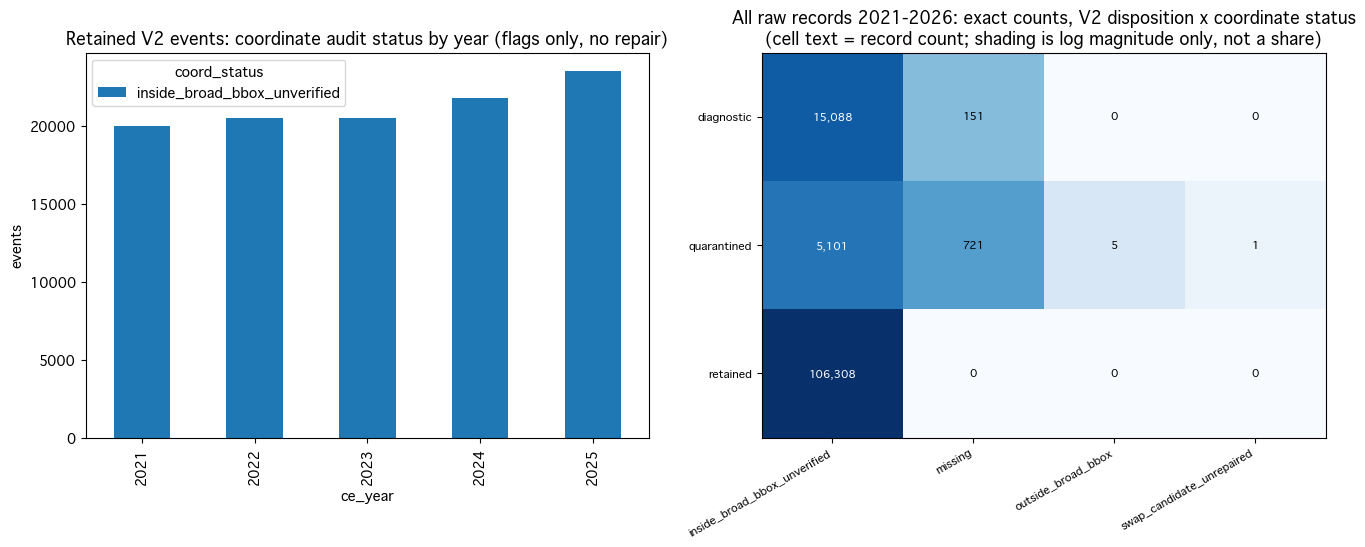

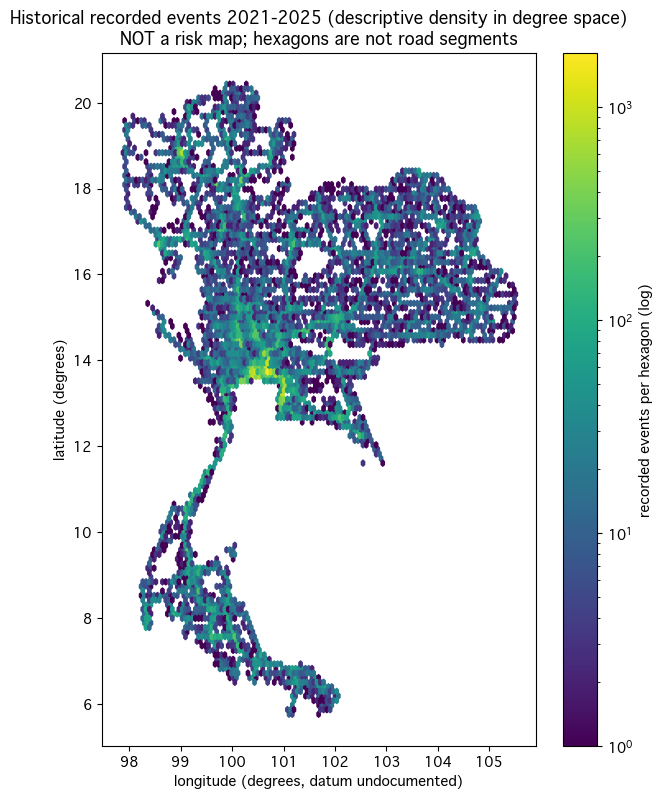

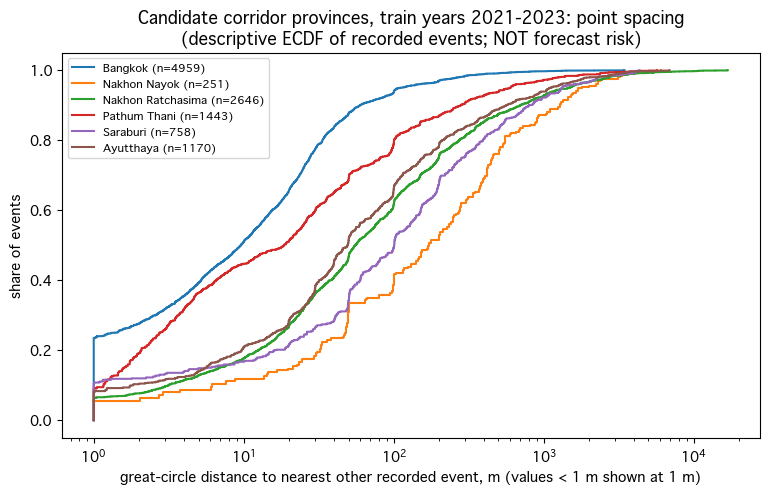

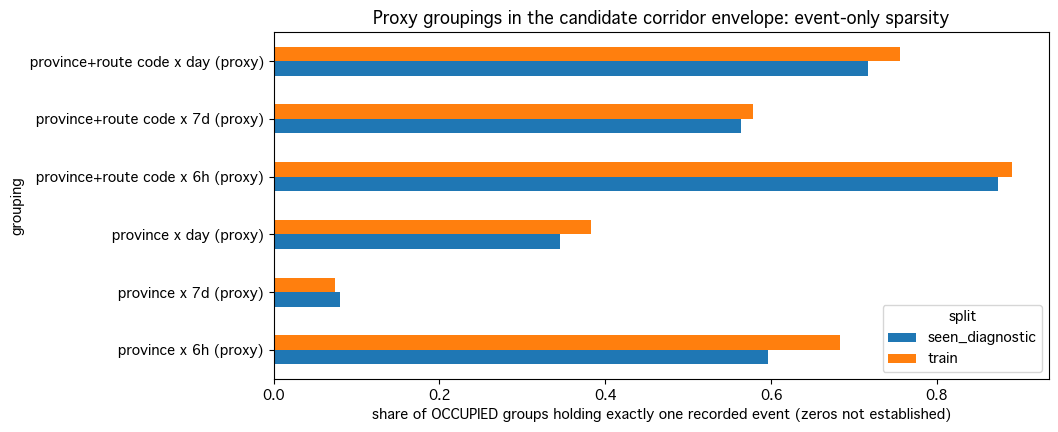

In [14]:
_fonts = {f.name for f in matplotlib.font_manager.fontManager.ttflist}
for _f in CFG['figure_fonts']:
    if _f in _fonts:
        plt.rcParams['font.family'] = _f
        break
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
COORD_RET.pivot_table(index='ce_year', columns='coord_status', values='n_events', aggfunc='sum', fill_value=0).plot(kind='bar', stacked=True, ax=axes[0])
axes[0].set_title('Retained V2 events: coordinate audit status by year (flags only, no repair)')
axes[0].set_ylabel('events')
# Raw records: annotated count matrix (no stacked log bars, which hide small components and imply false proportions).
_raw = COORD_RAW.pivot_table(index='v2_disposition', columns='coord_status', values='n_records', aggfunc='sum', fill_value=0)
_m = _raw.to_numpy()
axes[1].imshow(np.log10(_m + 1.0), cmap='Blues', aspect='auto')
axes[1].set_xticks(range(_m.shape[1]))
axes[1].set_xticklabels(_raw.columns, rotation=30, ha='right', fontsize=8)
axes[1].set_yticks(range(_m.shape[0]))
axes[1].set_yticklabels([s[:28] for s in _raw.index], fontsize=8)
_hi = np.log10(_m.max() + 1.0)
for (_i, _j), _v in np.ndenumerate(_m):
    axes[1].text(_j, _i, f'{int(_v):,}', ha='center', va='center', fontsize=8, color='white' if np.log10(_v + 1.0) > 0.6 * _hi else 'black')
axes[1].set_title('All raw records 2021-2026: exact counts, V2 disposition x coordinate status' + chr(10) + '(cell text = record count; shading is log magnitude only, not a share)')
save_fig(fig, 'fig_coordinate_status.png')

fig, ax = plt.subplots(figsize=(7, 9))
ok = RET[RET['_coord_ok']]
hb = ax.hexbin(ok['lon_value'], ok['lat_value'], gridsize=120, bins='log', mincnt=1, cmap='viridis')
fig.colorbar(hb, ax=ax, label='recorded events per hexagon (log)')
ax.set_xlabel('longitude (degrees, datum undocumented)')
ax.set_ylabel('latitude (degrees)')
ax.set_title('Historical recorded events 2021-2025 (descriptive density in degree space)' + chr(10) + 'NOT a risk map; hexagons are not road segments')
save_fig(fig, 'fig_retained_event_density_hexbin.png')

# Legend-only English names for the config candidate_corridor_provinces (V2 province_key, Thai): Thai combining marks render displaced
# in matplotlib legends (no text shaping engine). Tables, CSVs and the Thai report keep the original Thai province_key.
PROVINCE_EN = {'กรุงเทพมหานคร': 'Bangkok', 'ปทุมธานี': 'Pathum Thani', 'อยุธยา': 'Ayutthaya', 'สระบุรี': 'Saraburi',
               'นครนายก': 'Nakhon Nayok', 'นครราชสีมา': 'Nakhon Ratchasima'}
_unmapped = sorted(set(COR) - set(PROVINCE_EN))
if _unmapped:
    raise SpatialReadinessError(f'no English figure label for candidate provinces: {_unmapped}')
fig, ax = plt.subplots(figsize=(9, 5))
for prov, g in C[C['_coord_ok'] & C['split'].eq('train')].groupby('province_key'):
    nn, _ = nearest_neighbour_m(g['lat_value'], g['lon_value'], CFG['nn_max_points'])
    nn = np.sort(nn)
    ax.step(np.maximum(nn, 1.0), np.arange(1, len(nn) + 1) / len(nn), where='post', label=f'{PROVINCE_EN[prov]} (n={len(nn)})')
ax.set_xscale('log')
ax.set_xlabel('great-circle distance to nearest other recorded event, m (values < 1 m shown at 1 m)')
ax.set_ylabel('share of events')
ax.set_title('Candidate corridor provinces, train years 2021-2023: point spacing' + chr(10) + '(descriptive ECDF of recorded events; NOT forecast risk)')
ax.legend(fontsize=8)
save_fig(fig, 'fig_corridor_nn_ecdf.png')

fig, ax = plt.subplots(figsize=(10, 4.5))
(SUPPORT[SUPPORT['scope'] == 'candidate_corridor_envelope']
 .pivot_table(index='grouping', columns='split', values='share_occupied_groups_exactly_1_event').plot(kind='barh', ax=ax))
ax.set_xlabel('share of OCCUPIED groups holding exactly one recorded event (zeros not established)')
ax.set_title('Proxy groupings in the candidate corridor envelope: event-only sparsity')
save_fig(fig, 'fig_proxy_support.png')

## 9. บันทึกผล: row-level (gitignored) + รายงานไทย + manifest + ตรวจ hash หลังรัน

In [15]:
ADJ = f'flag_only_no_repair ({VERSION})'
ROW_COLS = (['event_uid', 'source_file', 'source_sha256', 'source_row', 'raw_index', 'be_year', 'ce_year', 'event_date', 'time_block',
             'province_key', 'split'] + ['raw_' + f for f in SPATIAL_FIELDS] +
            ['lat_value', 'lon_value', 'coord_status', 'lat_decimals', 'lon_decimals', 'low_precision_flag', 'lat_equals_lon_flag', 'coord_key',
             'n_events_same_coord', 'repeated_coord_flag', 'dist_to_province_event_median_km', 'far_from_province_event_median_flag',
             'route_key', 'route_format', 'km_format', 'km_value', 'km_status', 'km_parse_rule'])
RAW_COLS = (['source_file', 'source_row', 'ce_year', 'split', 'v2_disposition'] + ['raw_' + f for f in ('latitude', 'longitude', 'route_code', 'km')] +
            ['coord_status', 'low_precision_flag', 'repeated_coord_flag', 'route_format', 'km_format', 'km_status'])
for name, df in (('retained_spatial_linkage_v3.csv.gz', RET[ROW_COLS].assign(adjudication=ADJ)),
                 ('raw_records_spatial_flags_v3.csv.gz', ALLRAW[RAW_COLS].assign(adjudication=ADJ))):
    p = DATA_DIR / name
    df.to_csv(p, index=False, encoding='utf-8', compression={'method': 'gzip', 'mtime': 0})
    DATA_OUTPUTS.append({'path': name, 'rows': int(len(df)), 'sha256': sha256_file(p)})

GRID_LIBS = OPTIONAL_LIBS['pyproj'] and OPTIONAL_LIBS['h3']
BLOCKERS = [f'{r.capability}: {r.status} ({r.reason})' for r in CAPS.itertuples()]
BLOCKERS += ['zero labels for any location unit: NOT ESTABLISHED (no verified road universe or reporting coverage)',
             'coordinate datum/CRS: ' + ('keys found in source metadata, still unverified' if DATUM_KEYS_FOUND else 'NOT DOCUMENTED in source metadata (WGS84 not verified)'),
             'reporting latency for historical lags: NOT VERIFIED (lags blocked)',
             'local archived forecast weather with issue times: NOT COLLECTED',
             'traffic station-to-segment linkage: NOT POSSIBLE without road geometry',
             'projected CRS / H3 grid: ' + ('libraries present but no CRS chosen' if GRID_LIBS else 'pyproj/h3 not installed in .venv; no metric grid built')]
if N_YEAR_MISMATCH:
    BLOCKERS.append(f'{N_YEAR_MISMATCH} retained events have event_date year != source-file year (reported, not repaired)')
if len(PF_RECON) and not PF_RECON['match'].all():
    BLOCKERS.append(f'manager preflight not reproduced for {int((~PF_RECON.match).sum())} metrics (see preflight_reconciliation.csv)')
GEOMETRY_REQUIRED = bool((CAPS['status'] != 'VERIFIED').any())
NOT_VERIFIED = ['road geometry / road universe / stable segment IDs', 'point-in-province', 'road snapping and ambiguity handling',
                'true coordinate accuracy and datum', 'route-code / KM validity against a road', 'reporting completeness and zero labels',
                'any spatial model quality, calibration or colour thresholds']

HASH_AFTER = hash_tree(BACKEND, CFG['protected_paths'])
CHANGED = changed_keys(HASH_BEFORE, HASH_AFTER)
check('protected V2/raw/config/notebook inputs unchanged by the run', not CHANGED, CHANGED[:20], fatal=False)

EXPECTED = CFG['expected_retained_events']
N_INSIDE = int((RET['coord_status'] == 'inside_broad_bbox_unverified').sum())
N_SWAP = int((RET['coord_status'] == 'swap_candidate_unrepaired').sum())
REP_MIN = CA['repeated_min_events']
SEG_KM = CFG['segment_length_candidates_km']
GEO_REQ_TH = 'ใช่' if GEOMETRY_REQUIRED else 'ไม่'
DATUM_TH = 'ระบุ (ยังไม่ยืนยัน)' if DATUM_KEYS_FOUND else 'ไม่ระบุ'
N_GEO_FILES = int(GEO_SCAN['path'].ne('').sum())
GEO_FILES_TH = f'{N_GEO_FILES} ไฟล์ (ยังไม่ register จึงใช้ไม่ได้)' if N_GEO_FILES else 'ไม่พบ'
CATALOG_CLASSES = ', '.join(f'{k}: {v}' for k, v in CATALOG.groupby('format_class', dropna=False).size().items())
TRAIN_SUPPORT = SUPPORT[(SUPPORT.scope == 'candidate_corridor_envelope') & (SUPPORT.split == 'train')][
    ['grouping', 'n_space_keys_observed', 'n_occupied_groups', 'share_occupied_groups_exactly_1_event', 'events_per_occupied_group_p50',
     'events_per_occupied_group_p90']]
NATIONAL_BUDGET = BUDGET[BUDGET.scope == 'all_retained_national'][['split', 'grouping', 'n_space_keys_observed', 'n_periods',
                                                                   'crossproduct_cells_if_built', 'within_budget']]
FAR_RULE = FLAGS['far_rule'].iloc[0]

L = ['# รายงานความพร้อมข้อมูลเชิงพื้นที่ RoadAware (V3 audit)', '',
     f'สร้าง {STARTED_UTC} UTC · config `{VERSION}` · notebook `16_spatial_data_readiness.ipynb`', '',
     '**สถานะ: audit/feasibility เท่านั้น** ไม่มีการ fit โมเดล ไม่มี threshold/สี ไม่มีการดาวน์โหลด ผล V2 (province daily/6h) ไม่ได้ยืนยันความสามารถรายพื้นที่ '
     'ปี 2024/2025 เป็น seen diagnostic ปี 2026 (ไม่มี ID) เป็น diagnostic เท่านั้น ไม่มี untouched future test', '',
     '## 1. Raw linkage', '',
     f'เชื่อม V2 retained events ได้ **{len(RET):,}/{EXPECTED:,}** แบบ 1:1 (source_file/source_row → data index source_row−2, BE-year:ACC_CODE ตรงทุกแถว, '
     f'ไม่มี raw record ถูกใช้ซ้ำ) · event_date ปีไม่ตรงกับปีไฟล์: {N_YEAR_MISMATCH} (รายงานเท่านั้น ไม่แก้)', '',
     md_table(LINK_RECON[['source_file', 'ce_year', 'split', 'n_linked', 'raw_records', 'n_event_year_ne_file_year']]), '',
     '## 2. พิกัด / สายทาง / KM (flag เท่านั้น ไม่แก้ค่า)', '',
     f'retained: inside broad bbox (ยังไม่ยืนยันถนน/จังหวัด/datum) {N_INSIDE:,} · swap candidate (ไม่สลับให้) {N_SWAP} · datum ในแหล่งข้อมูล: {DATUM_TH}', '',
     md_table(COORD_RET.pivot_table(index='coord_status', columns='ce_year', values='n_events', aggfunc='sum', fill_value=0).reset_index()), '',
     'raw ทุกแถวตาม disposition เดิมของ V2 (ไม่เขียนทับ disposition):', '',
     md_table(COORD_RAW.groupby(['v2_disposition', 'coord_status'])['n_records'].sum().reset_index()), '',
     md_table(FLAGS.drop(columns='far_rule')), '', f'far rule: {FAR_RULE}', '',
     f'จุดพิกัดซ้ำ (≥{REP_MIN} เหตุ): {REPEATED_SUMMARY} — ไม่ถือว่าเป็นเหตุซ้ำ อาจเป็นจุด default/landmark/ปัดเศษ หรือ hotspot จริง', '',
     'รูปแบบ KM (ตัวเลข = km ตามหัวคอลัมน์; `a+b` = a km + b m เป็นสมมติฐานที่บันทึกไว้; comma กำกวมจึงไม่ parse):', '',
     md_table(KM_FMT.groupby(['km_format', 'km_status'])['n_events'].sum().reset_index()), '',
     md_table(ROUTE_FMT.groupby('route_format')['n_events'].sum().reset_index()), '',
     '## 3. Geometry ที่มีในเครื่อง', '',
     md_table(CAPS), '', md_table(GEO_REGISTRY[['source_id', 'role', 'format', 'status', 'license', 'version']]), '',
     f'ไฟล์ geometry ที่พบในเครื่อง: {GEO_FILES_TH} · catalog snapshot ในเครื่อง (metadata เท่านั้น): {CATALOG_CLASSES}', '',
     'แผนเก็บ geometry (ขั้นถัดไปที่ Codex ควบคุม ต้องใช้ network): (1) ตรวจว่า MOT transportgis มี vector/API + license ไม่ใช่เฉพาะ WMS ภาพ '
     '(2) ถ้าไม่มี ใช้ OSM snapshot ที่ลงวันที่ + ODbL attribution โดยไม่เรียกว่าเป็นโครงข่าย MOT ครบ (3) polygon จังหวัด geoBoundaries ADM1 ที่ pin commit '
     '(4) pin sha256 ใน config แล้ว audit CRS/vintage/coverage/stable ID ก่อนใช้', '',
     '## 4. Candidate corridor envelope (ไม่ใช่เส้นทาง SPU–เขาใหญ่ที่ routing แล้ว)', '',
     md_table(COR_SPLIT), '', 'การกระจายพิกัด (great-circle; median event point ไม่ใช่ centroid ของ polygon):', '', md_table(COR_DISP), '',
     'Reconcile กับ preflight ของ manager:', '', md_table(PF_RECON), '',
     f'ช่วงถนน {SEG_KM} km เป็นข้อเสนอจนกว่าจะมี road inventory; ไม่สร้าง segment ID จาก cluster ของเหตุ', '',
     '## 5. ความเบาบาง (proxy, train 2021–2023, corridor envelope)', '',
     md_table(TRAIN_SUPPORT), '', f'zero labels: **{ZERO_NOT_ESTABLISHED}** — ไม่มีการสร้าง zero และไม่ train', '',
     md_table(NATIONAL_BUDGET), '',
     'V2 province-day panel (บริบทเท่านั้น; eligibility มาจาก outcome ใช้เป็น coverage รายพื้นที่ไม่ได้):', '', md_table(PANEL_CTX.drop(columns='meaning')), '',
     '## 6. Spatial universe / geocoding / snap quality ที่ต้องมีในขั้นถัดไป', '',
     '- Road universe ของพื้นที่ศึกษา รวมช่วงที่ไม่เคยมีเหตุ เป็นตัวหาร; แยก observed zero / unknown reporting / outside network',
     '- Snap: รหัสสายทางตรง + KM สอดคล้อง + ระยะ snap ไม่เกินเกณฑ์ที่กำหนดจาก training; สถานะ matched / ambiguous / unmatched / parallel-road / '
     'grade-separated; ห้าม snap ถนนใกล้สุดแบบไม่มีเงื่อนไข; reconcile จำนวนทุกสถานะ',
     '- ทั้งหมดนี้ **BLOCKED / NOT VERIFIED** ในรอบนี้เพราะไม่มี geometry ที่ตรวจ hash', '',
     '## 7. Feature readiness', '', md_table(FEAT[['feature_group', 'status', 'geographic_resolution', 'reason']], 60), '',
     '## 8. Blockers', ''] + ['- ' + b for b in BLOCKERS] + ['',
     '## 9. ข้อเสนอ protocol ถัดไป (PROPOSED — Codex ต้องตรวจและล็อกก่อน)', '',
     f'- **ต้องเก็บ geometry ก่อนทำโมเดลระดับถนน: {GEO_REQ_TH}** ระหว่างนี้ grid/H3 ทำได้เฉพาะเป็น area-level experiment หลังอนุมัติ pyproj/h3 และเลือก CRS',
     '- หน่วยที่ควรทดสอบ: segment 0.5/1/2 km × วัน และ × 6 ชม. (เลือกจาก support ใน training เท่านั้น); 7 วันเป็น target แยกที่ไม่อ้างความเสี่ยงรายชั่วโมง',
     '- Folds: expanding chronological ภายใน 2021–2023; 2024/2025 คง seen diagnostic; spatial group holdout + buffer ที่กำหนดจาก training',
     '- Baselines: zero, train-only global/road-type mean, smoothed segment/time mean + fallback; Poisson GLM / RF Poisson / HGB Poisson ประเมินใหม่ ไม่ถือว่า HGB ชนะ',
     '- Alert layer: ระดับเฝ้าระวังแบบ relative ของ expected recorded count (cutoff จาก training/OOF ภายหลัง); สีเทา missing/out-of-coverage มาก่อนเสมอ; '
     'severity และ personal probability แยก; ไม่มีตัวเลขความแม่นยำ/ความน่าจะเป็นในรายงานนี้', '',
     '## 10. ทำซ้ำได้อย่างไร', '',
     '- `.venv/bin/python backend/scripts/run_spatial_readiness.py --output-dir backend/rerun-spatial-<UTC>` (ไม่ใช้ network, ไม่เขียนทับรอบเดิม)',
     '- `.venv/bin/python -m pytest backend/tests/test_spatial_readiness_notebook.py -q`',
     f'- protected inputs เปลี่ยนระหว่างรัน: {len(CHANGED)} ไฟล์', '',
     '## ยังไม่ได้ยืนยัน (NOT VERIFIED)', ''] + ['- ' + n for n in NOT_VERIFIED]
REPORT_MD = chr(10).join(L) + chr(10)
(REPORT_DIR / 'spatial_readiness_report_th.md').write_text(REPORT_MD, 'utf-8')
OUTPUTS.append({'path': 'spatial_readiness_report_th.md', 'rows': None, 'sha256': sha256_file(REPORT_DIR / 'spatial_readiness_report_th.md')})
MANIFEST = {'version': VERSION, 'purpose': 'spatial data readiness audit; not a model, threshold or spatial acceptance',
            'started_utc': STARTED_UTC, 'finished_utc': dt.datetime.now(dt.timezone.utc).isoformat(),
            'status': 'complete' if not CHANGED else 'FAILED_protected_inputs_changed',
            'config_sha256': sha256_file(CONFIG_PATH), 'offline': OFFLINE, 'output_root_is_backend': OUTPUT_ROOT == BACKEND,
            'environment': {'python': sys.version.split()[0], 'platform': platform.platform(), 'pandas': pd.__version__, 'numpy': np.__version__,
                            'matplotlib': matplotlib.__version__, 'optional_libraries': OPTIONAL_LIBS},
            'input_sha256': INPUT_HASHES, 'protected_files_hashed': len(HASH_BEFORE), 'protected_changed': CHANGED,
            'linkage': {'retained_events_linked': len(RET), 'raw_records_audited': len(ALLRAW), 'event_year_ne_file_year': N_YEAR_MISMATCH,
                        'lineage_info': LIN_INFO, 'headers_by_field': HEADERS},
            'repeated_coordinates': REPEATED_SUMMARY, 'capabilities': CAPS.to_dict('records'),
            'zero_label_status': ZERO_NOT_ESTABLISHED, 'geometry_collection_required_before_segment_modelling': GEOMETRY_REQUIRED,
            'checks': CHECKS, 'blockers': BLOCKERS, 'not_verified': NOT_VERIFIED, 'report_outputs': OUTPUTS,
            'row_level_outputs_gitignored': DATA_OUTPUTS, 'no_model_fit': True, 'no_network': True}
MANIFEST_PATH.write_text(json.dumps(to_jsonable(MANIFEST), indent=2, ensure_ascii=False, allow_nan=False) + chr(10), 'utf-8')
print(f'report: {REPORT_DIR} | row-level: {DATA_DIR} | checks: {len(CHECKS)} | protected changed: {len(CHANGED)}')
display(pd.DataFrame(CHECKS))
if CHANGED:
    raise SpatialReadinessError(f'protected inputs changed during the run: {CHANGED[:20]}')

report: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-spatial-012-003/reports/v3/spatial_readiness | row-level: /Users/earthnaja/Documents/GitHub/Work - Earth/Project Work/Source Code/RoadAware/backend/rerun-spatial-012-003/data/v3/spatial_readiness | checks: 27 | protected changed: 0


,check,status,value,note
0,events_v2 equals the accepted notebook 10 data...,pass,f80c217fd0065fa90683d15ea36789146c3fd0307a6c70...,
1,row_lineage_v2 equals the accepted notebook 10...,pass,9333f7bccb2b862f572ae7a75636c12d9f0ca33d9102cf...,
2,panel_daily_v2 equals the accepted notebook 10...,pass,125dd344d5aab4ff9a4e5338aaf49f804a2f569d7be472...,
3,raw source_manifest equals the copy notebook 1...,pass,[708a3607231e4ee2f801f800defcd78ba05fdc60b886c...,
4,accidents_2564_original.csv: source_manifest h...,pass,044f8ae0a918ec25139bef24257fe274fd17d9bfab2512...,
5,accidents_2564_original.csv: record count equa...,pass,20062,
6,accidents_2565_original.csv: source_manifest h...,pass,6f7c543a302906925e32fbf6b8da5d2b1920266489ae1c...,
7,accidents_2565_original.csv: record count equa...,pass,20566,
8,accidents_2566_original.csv: source_manifest h...,pass,4d6dbfa4b8e1f4dd476d81062a01c10a858b7acd174fef...,
9,accidents_2566_original.csv: record count equa...,pass,23841,
